# 05 Geospatial and Temporal Analysis
This notebook will load the compiled parquets from `03_feature_engineering.ipynb` and do the following:
1. Geo-spatial visualisations using `geopandas` (where are trips, ridership, stations, and alerts concentrated?)
    - spatial context: location and geo-spatial density in each zone of the data we're analysing
    - `n_trips_taxi` and `n_trips_fhvhv` in each zone, summed over the given time range
    - `n_stations` in each zone 
    - `n_alerts` in each zone, summed over the given time range by each `borough`
    - `ridership` in each zone, summed over the given time range 
2. Temporal visualisations (when do alerts and ridership vary across boroughs?)
    - temporal context: `n_trips_taxi` and `n_trips_fhvhv` across 2025 Jan - 2026 May (take a month average for simplicity)
    - `n_trips_taxi` and `n_trips_fhvhv` averages across each hour of the day / day of week by each `borough`
    - `n_alerts` average across each hour of the day / day of week by each `borough`
    - `ridership` average across each hour of the day / day of week by each `borough`


In [1]:
# Restart spark if required
try:
    spark.stop()
except NameError:
    pass
except Exception:
    pass

from pyspark.sql import SparkSession

# Create a spark session (which will run spark jobs)
spark = (
    SparkSession.builder.appName("MAST30034 Project 1")
    .config("spark.sql.repl.eagerEval.enabled", True) 
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "America/New_York") # timezone set to NYC
    .getOrCreate()
)
spark.conf.set("spark.sql.shuffle.partitions", "800")
spark.conf.set("spark.sql.adaptive.enabled", "true")

spark.sparkContext.setLogLevel("ERROR") # silence warnings

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/08/30 02:01:20 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/08/30 02:01:21 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/08/30 02:01:21 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/08/30 02:01:21 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


## Set up and configuration

In [2]:
# Imports
from pathlib import Path
from pyspark.sql import functions as F
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler

import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


In [3]:
# Raw spatial data from `01_fetch_data.ipynb`
taxi_zones_path = "../data/raw/taxi_zones/taxi_zones.shp"

# Input directories from `02_preprocess_data.ipynb`
processed_dir = "../data/processed"

# Input directories from `03_feature_engineering.ipynb`
features_dir = "../data/features"

# Output directories for `05_exploratory_analysis.ipynb`
analysis_dir = "../data/analysis"

In [4]:
sdf_tlc_hourly = spark.read.parquet(f"{features_dir}/tlc_zone_hourly_final")

## Geo-spatial visualisations
We need to pull the `zones` dataset and use geopandas for coordinates. 

In [5]:
# Read in required data
zones = gpd.read_file(taxi_zones_path)[["LocationID", "borough", "zone", "geometry"]]
sdf_station_zones = spark.read.parquet(f"{features_dir}/station_zones")
sdf_ridership = spark.read.parquet(f"{processed_dir}/mta_ridership")

# Define colours for each borough
borough_palette = {
    "Bronx": "#1f77b4",
    "Brooklyn": "#ff7f0e",
    "Manhattan": "#2ca02c",
    "Queens": "#d62728",
    "Staten Island": "#9467bd",
}
borough_order = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]

# Define boundaries for boroughs for plotting
borough_boundaries = zones.dissolve(by="borough").boundary
borough_shapes = zones[zones["borough"].isin(borough_order)].dissolve(by="borough")

# Keep NYC boroughs relevant for this context map
zones = zones[zones["borough"].isin(borough_order)].copy()

# Set up station point GeoDataFrame
stations = sdf_ridership.select(
    "station_complex_id",
    "station_complex",
    F.col("borough").alias("mta_borough"),
    "latitude",
    "longitude"
).distinct().toPandas()

stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations["longitude"], stations["latitude"]),
    crs="EPSG:4326"
).to_crs(zones.crs)

# Count mapped subway station complexes per TLC taxi zone
station_counts_pd = (
    sdf_station_zones
    .groupBy("PULocationID")
    .agg(F.countDistinct("station_complex_id").alias("n_stations_mapped"))
    .toPandas()
)

zones = zones.merge(
    station_counts_pd,
    left_on="LocationID",
    right_on="PULocationID",
    how="left"
)

zones["n_stations_mapped"] = zones["n_stations_mapped"].fillna(0).astype(int)
zones["has_station"] = zones["n_stations_mapped"] > 0

/Users/hannahluo/miniconda3/envs/mast30034/lib/python3.10/site-packages/shapely/set_operations.py:553: RuntimeWarning: invalid value encountered in unary_union
  return lib.unary_union(collections, **kwargs)
/Users/hannahluo/miniconda3/envs/mast30034/lib/python3.10/site-packages/shapely/set_operations.py:553: RuntimeWarning: invalid value encountered in unary_union
  return lib.unary_union(collections, **kwargs)


### Spatial context
First, visualise the zones and geo-spatial density of our data. The subway and zones overlap clearly shows the zones within which we conduct our analysis. Importantly, Staten Island has no zones with stations, and some zones of other boroughs are also excluded where they don't have at least one station. 

In [ ]:
def blend_with_white(hex_color, amount):
    """
    Helper function for plotting with single colour gradients.
    amount=0 gives white, amount=1 gives chosen colour.
    """
    rgb = np.array(mcolors.to_rgb(hex_color))
    white = np.array([1, 1, 1])
    return white * (1 - amount) + rgb * amount 

max_station_count = zones["n_stations_mapped"].max()

# Create borough-specific heat colours:
# lighter shade = fewer/no mapped stations, darker shade = more mapped stations
def zone_colour(row):
    base = borough_palette.get(row["borough"], "#bdbdbd")
    if row["n_stations_mapped"] == 0:
        amount = 0.08
    else:
        amount = 0.25 + 0.65 * (row["n_stations_mapped"] / max_station_count)
    return blend_with_white(base, amount)

zones["plot_colour"] = zones.apply(zone_colour, axis=1)

In [7]:
# Compute number of TLC taxi zones with at least one mapped subway station by borough
zone_station_stats = (
    zones
    .groupby("borough")
    .agg(
        n_zones=("LocationID", "count"),
        n_zones_with_station=("has_station", "sum")
    )
    .reindex(borough_order)
    .reset_index()
)

stats_text = "\n".join(
    f"{row.borough:<13} {int(row.n_zones_with_station):>2}/{int(row.n_zones):<2} zones"
    for row in zone_station_stats.itertuples()
)

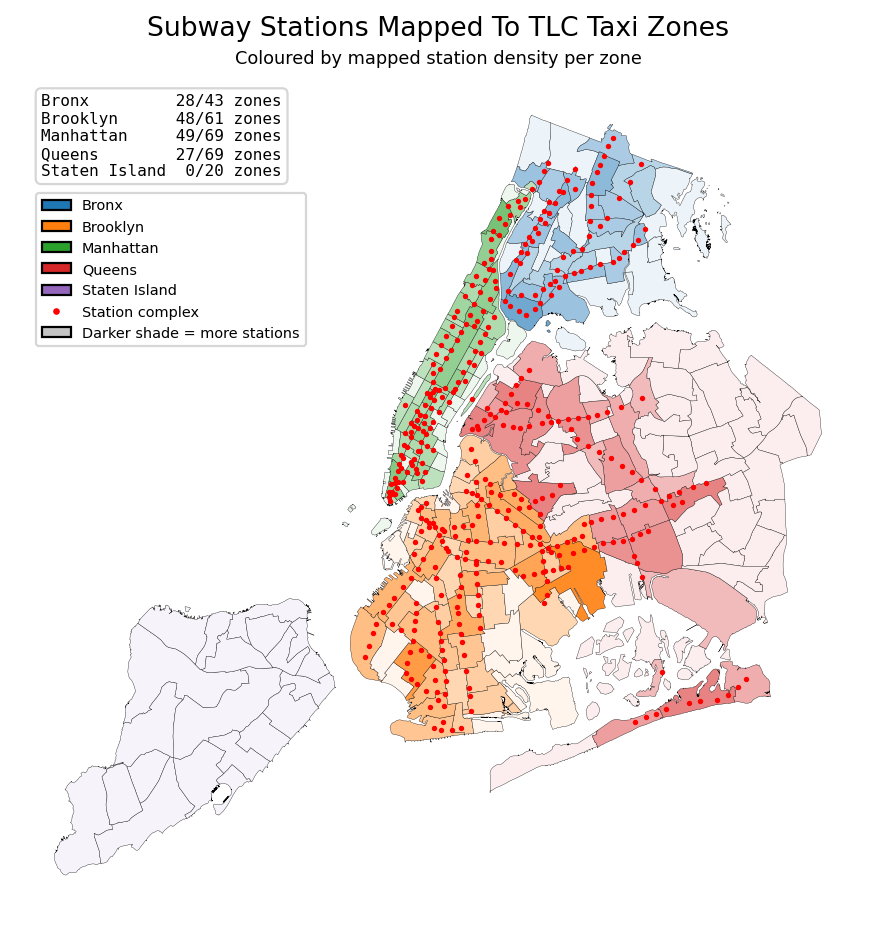

In [8]:
# Visualise zones with subway stations mapped
fig, ax = plt.subplots(figsize=(6, 6), dpi=160)

zones.plot(
    ax=ax,
    color=zones["plot_colour"],
    edgecolor="black",
    linewidth=0.15
)

stations.plot(
    ax=ax,
    color="red",
    markersize=2
)

# Stats textbox
ax.text(
    0.03,
    0.98,
    stats_text,
    transform=ax.transAxes,
    fontsize=7.2,
    va="top",
    ha="left",
    family="monospace",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="lightgrey",
        alpha=0.92
    )
)

# Colour / symbol legend
borough_handles = [
    Patch(facecolor=borough_palette[b], edgecolor="black", label=b)
    for b in borough_order
]

station_handle = Line2D(
    [0], [0],
    marker="o",
    color="w",
    markerfacecolor="red",
    markersize=4,
    label="Station complex"
)

shade_handle = Patch(
    facecolor=blend_with_white("#555555", 0.35),
    edgecolor="black",
    label="Darker shade = more stations"
)

ax.legend(
    handles=borough_handles + [station_handle, shade_handle],
    loc="upper left",
    bbox_to_anchor=(0.015, 0.87),  # just below stats box
    fontsize=6.5,
    frameon=True
)

fig.suptitle("Subway Stations Mapped To TLC Taxi Zones", fontsize=12, y=0.96)
ax.set_title("Coloured by mapped station density per zone", fontsize=8, pad=6)
ax.axis("off")
plt.tight_layout()
plt.show()

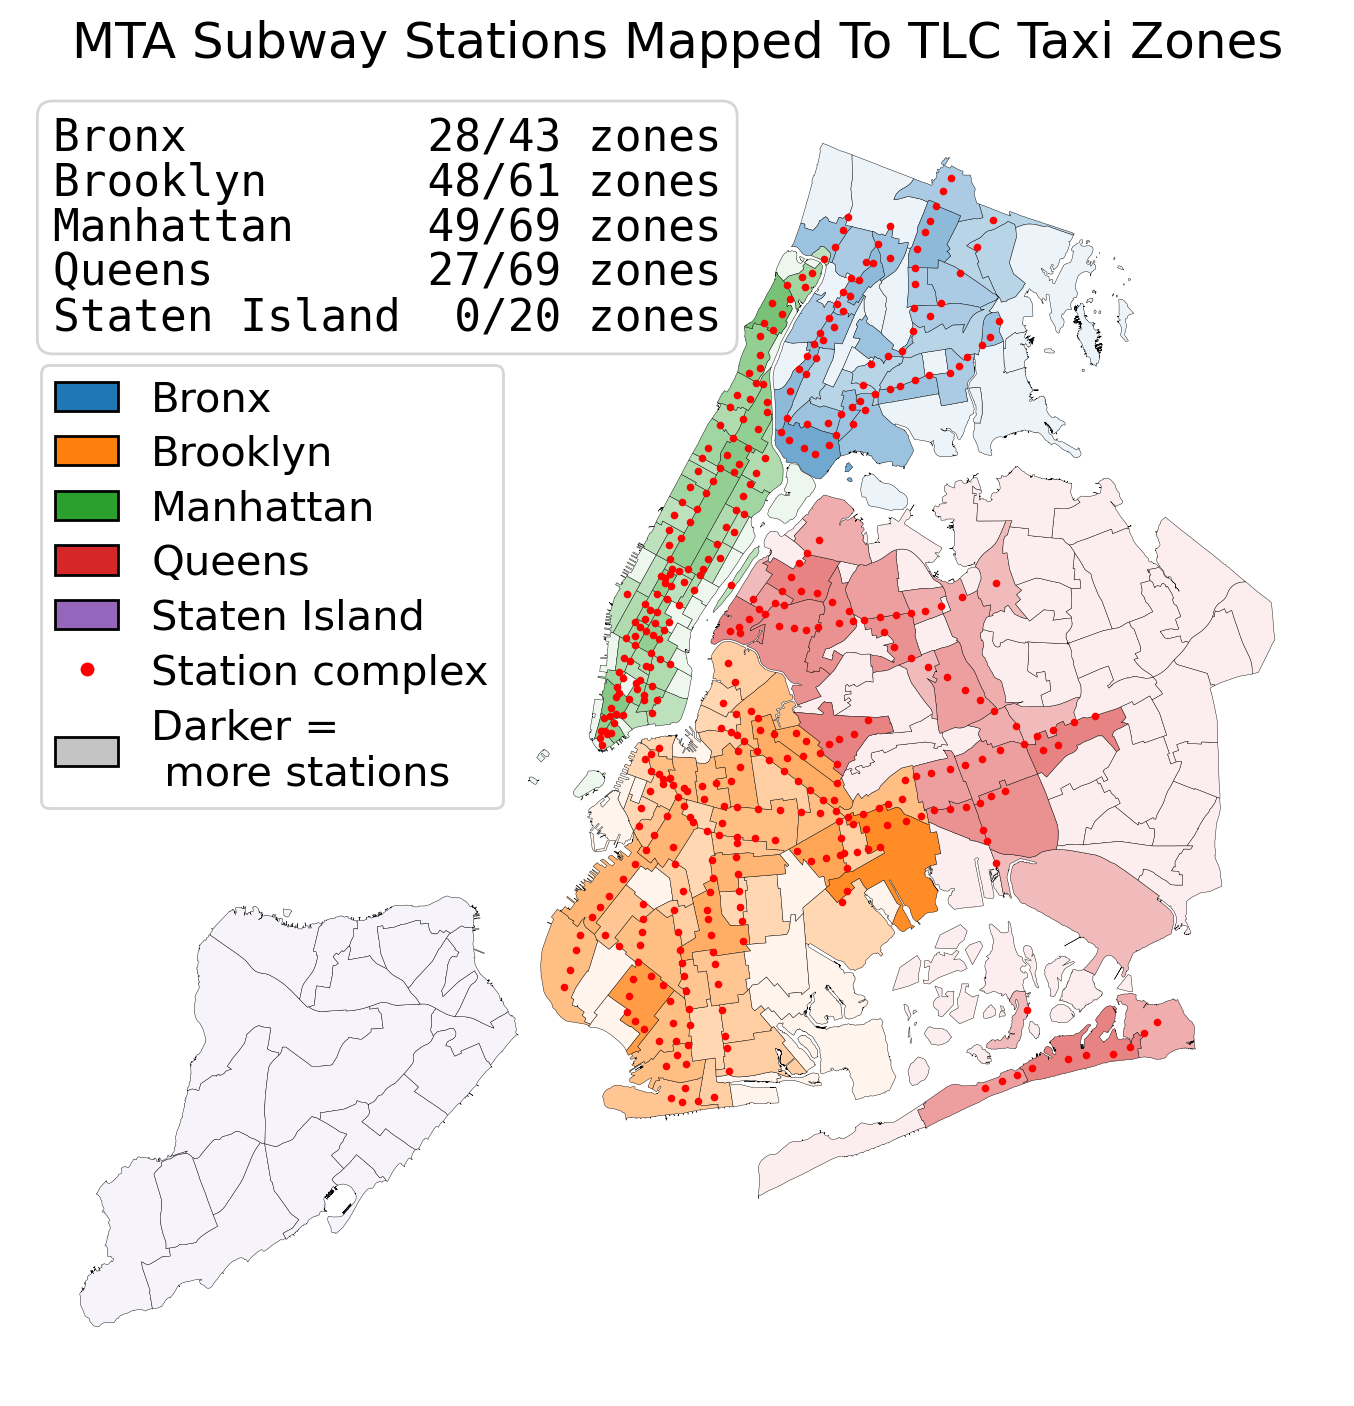

In [ ]:
# Report friendly version for better readability!
# Visualise zones with subway stations mapped
fig, ax = plt.subplots(figsize=(7.2, 7.2), dpi=200)

zones.plot(
    ax=ax,
    color=zones["plot_colour"],
    edgecolor="black",
    linewidth=0.15
)

stations.plot(
    ax=ax,
    color="red",
    markersize=3
)
    
# Stats textbox
ax.text(
    0.025,
    0.975,
    stats_text,
    transform=ax.transAxes,
    fontsize=16,
    va="top",
    ha="left",
    family="monospace",
    linespacing=1.05,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="lightgrey",
        alpha=0.94
    )
)

# Colour / symbol legend
borough_handles = [
    Patch(facecolor=borough_palette[b], edgecolor="black", label=b)
    for b in borough_order
]

station_handle = Line2D(
    [0], [0],
    marker="o",
    color="w",
    markerfacecolor="red",
    markersize=6,
    label="Station complex"
)

shade_handle = Patch(
    facecolor=blend_with_white("#555555", 0.35),
    edgecolor="black",
    label="Darker = \n more stations"
)

ax.legend(
    handles=borough_handles + [station_handle, shade_handle],
    loc="upper left",
    bbox_to_anchor=(0, 0.80),
    fontsize=15,
    frameon=True,
    borderpad=0.35,
    labelspacing=0.35,
    handlelength=1.5
)

fig.suptitle("MTA Subway Stations Mapped To TLC Taxi Zones", fontsize=18, y=0.97)
ax.axis("off")
plt.tight_layout()
plt.show()

The station-zone overlap visualisation shows the distribution of stations across the boroughs of New York. The number of stations per zone is between 0 and 10. If using zone-level MTA subway attributes (`ridership`, `n_alert`), may need to adjust by taking into account `n_stations` in each zone. 

### Spatial distribution of attributes 
We will visualise the distribution of numerical attributes `n_trips`, `n_stations`, `n_alerts`, `ridership` summed over the given time range (2025 Jan - 2026 May) where applicable. 
- `n_trips` are split into `n_trips_taxi` and `n_trips_fhvhv`, visualised as facet plots for comparison 
- `n_alerts`, `ridership` are log1p transformed as totals are highly skewed

In [10]:
# Aggregate hourly panel to zone-level totals over full study period
zone_metrics_pd = (
    sdf_tlc_hourly
    .groupBy("PULocationID")
    .agg(
        F.sum("n_trips_taxi").alias("total_taxi_trips"),
        F.sum("n_trips_fhvhv").alias("total_fhvhv_trips"),
        F.max("n_stations").alias("n_stations"),
        F.sum("n_alerts").alias("total_alerts"),
        F.sum("ridership").alias("total_ridership"),
        F.sum("disruption_severity").alias("total_disruption")
    )
    .toPandas()
    .rename(columns={"PULocationID": "LocationID"})
)

zone_metrics_geo = zones.merge(
    zone_metrics_pd,
    on="LocationID",
    how="left"
)

# Only create log values where a zone has data; leave zones outside scope as NaN/white
for col in ["total_taxi_trips", "total_fhvhv_trips", "total_alerts", "total_ridership", "total_disruption"]:
    zone_metrics_geo[f"log1p_{col}"] = np.where(
        zone_metrics_geo[col].notna(),
        np.log1p(zone_metrics_geo[col]),
        np.nan
    )

missing_kwds = {
    "color": "white",
    "edgecolor": "black",
    "label": "No mapped station / outside analysis scope",
}

#### Total trips by TLC Taxi Zone, Jan 2025 - May 2026

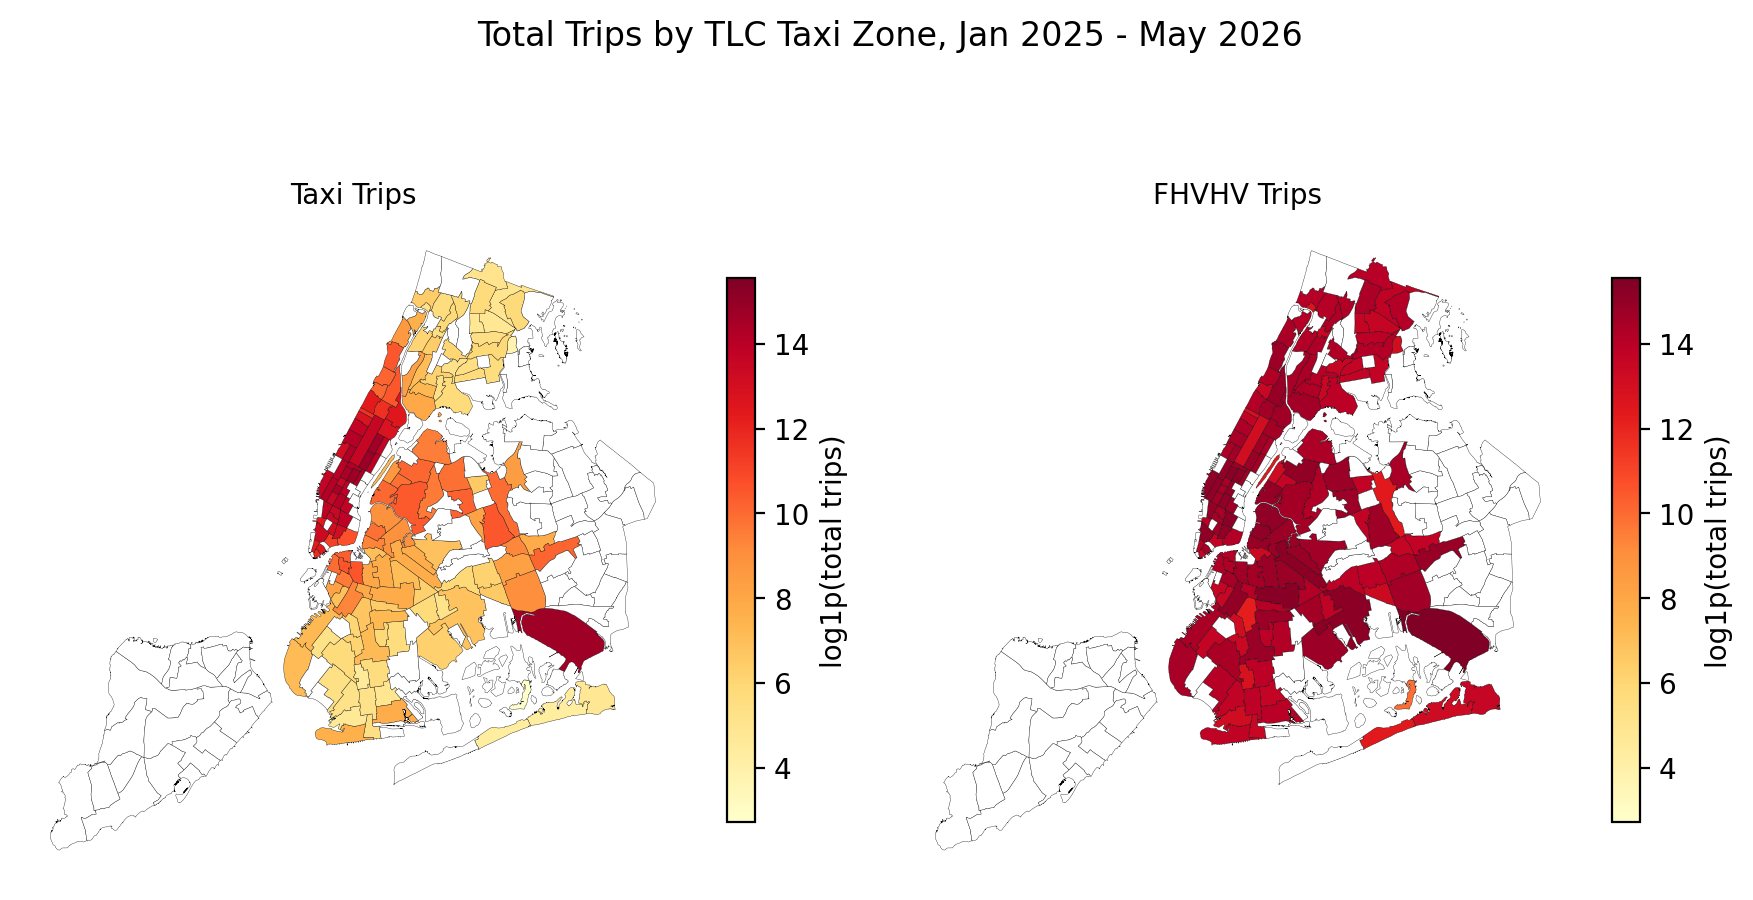

In [ ]:
# Set common scale for facet plot `n_trips_taxi` and `n_trips_fhvhv`
trip_cols = ["log1p_total_taxi_trips", "log1p_total_fhvhv_trips"]

# Use the scale for taxi and FHVHV trips for visual comparison (will be a lot less variable for FHVHV)
trip_vmin = zone_metrics_geo[trip_cols].min().min()
trip_vmax = zone_metrics_geo[trip_cols].max().max()

# Facet map to show spatial distribution of summed `n_trips` between 2025 Jan - 2026 May
fig, axes = plt.subplots(1, 2, figsize=(9, 4.8), dpi=200)

trip_maps = {
    "log1p_total_taxi_trips": "Taxi Trips",
    "log1p_total_fhvhv_trips": "FHVHV Trips",
}

for ax, (col, title) in zip(axes, trip_maps.items()):
    zone_metrics_geo.plot(
        ax=ax,
        column=col,
        cmap="YlOrRd",
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        vmin=trip_vmin,
        vmax=trip_vmax,
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": "log1p(total trips)"}
    )
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle("Total Trips by TLC Taxi Zone, Jan 2025 - May 2026", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

For `n_trips` from taxi vs. from FHVHV (log1p transformed to account for 0-count), taxi trips are much more variable between zones compared with FHVHV trips. For zone 132 (airport) in Queens and Downtown Manhattan, total taxi trips peaks. Total FHVHV trips are more evenly distributed across all applicable zones, with the small excpetion of zone 30 in Queens.

#### Total MTA Subway Ridership by TLC Taxi Zone, Jan 2025 - May 2026

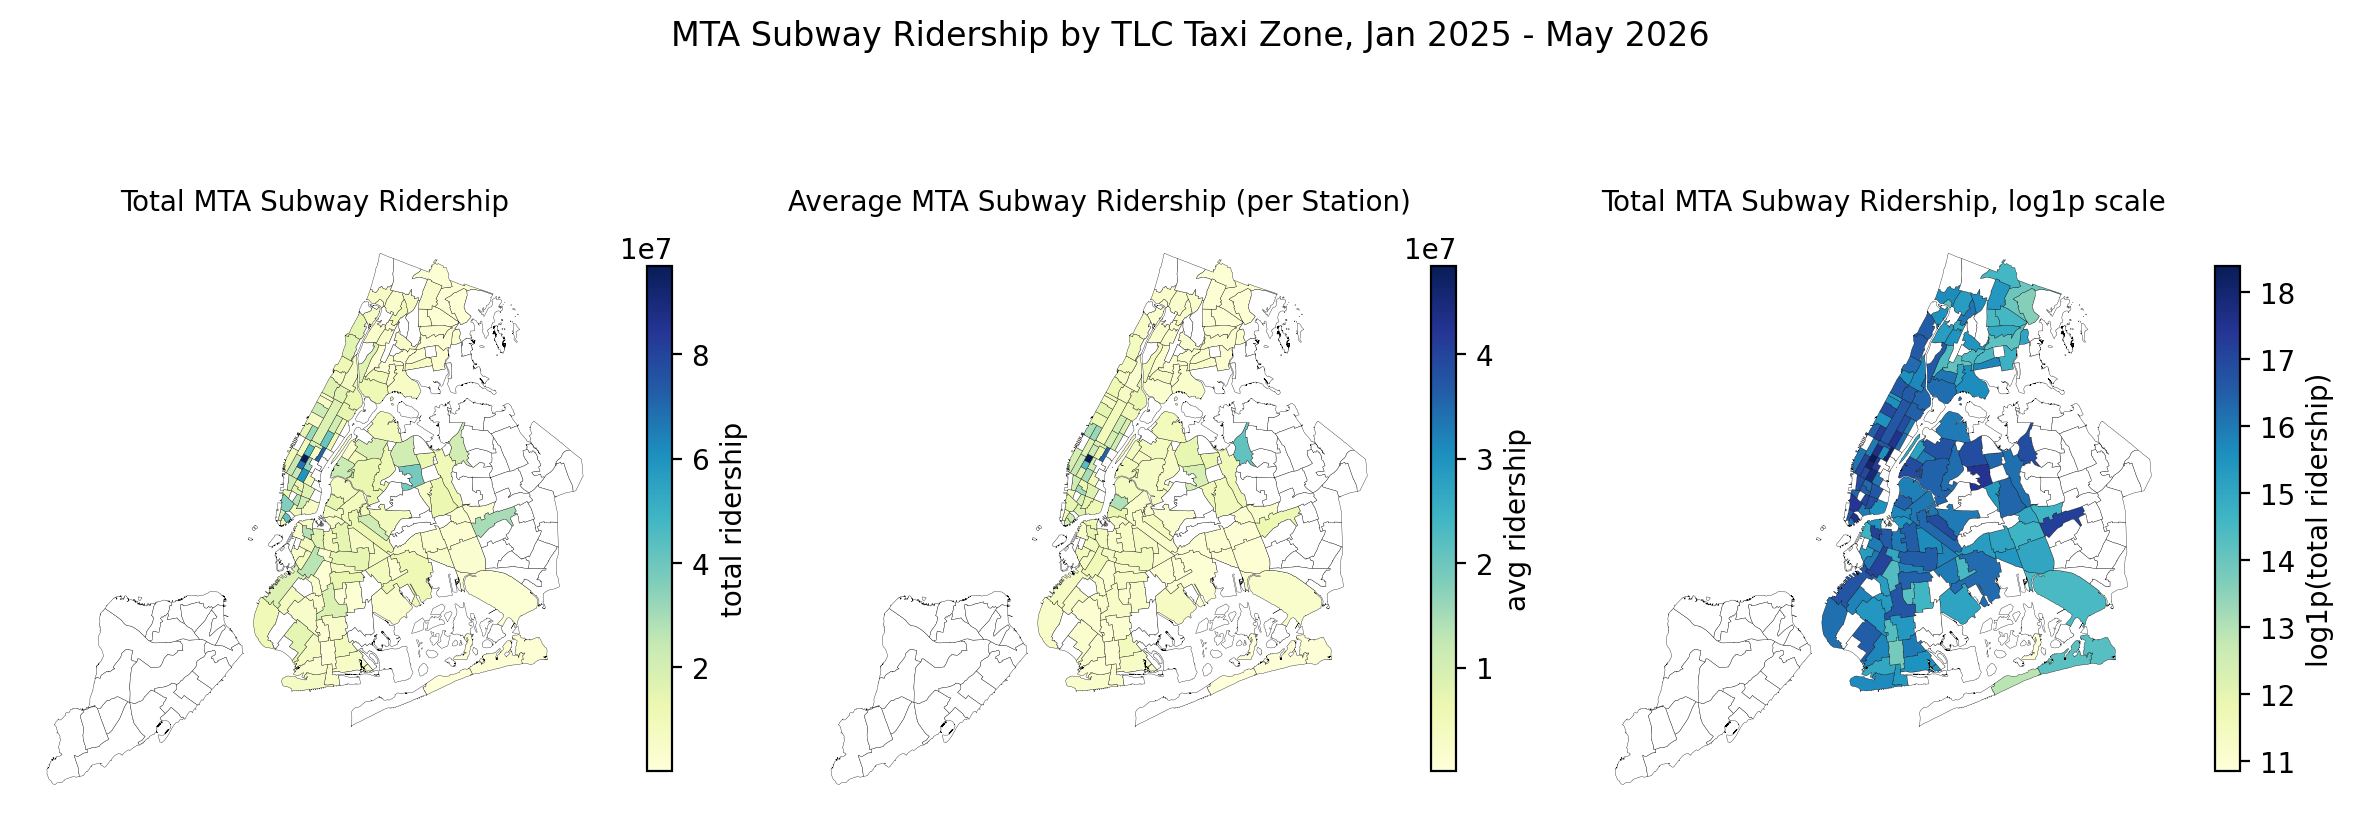

In [12]:
# Average ridership per mapped subway station in each TLC taxi zone (take into account n_stations)
zone_metrics_geo["avg_ridership_per_station"] = np.where(
    (zone_metrics_geo["n_stations"].notna()) & (zone_metrics_geo["n_stations"] > 0),
    zone_metrics_geo["total_ridership"] / zone_metrics_geo["n_stations"],
    np.nan
)

# Maps to show spatial distribution of summed and average `ridership` between 2025 Jan - 2026 May
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=200)

ridership_map_specs = [
    ("total_ridership", "Total MTA Subway Ridership", "total ridership", "YlGnBu"),
    ("avg_ridership_per_station", "Average MTA Subway Ridership (per Station)", "avg ridership", "YlGnBu"),
    ("log1p_total_ridership", "Total MTA Subway Ridership, log1p scale", "log1p(total ridership)", "YlGnBu")
]

for ax, (col, title, legend_label, cmap) in zip(axes, ridership_map_specs):
    zone_metrics_geo.plot(
        ax=ax,
        column=col,
        cmap=cmap,
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": legend_label}
    )
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle("MTA Subway Ridership by TLC Taxi Zone, Jan 2025 - May 2026", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

We show both total and average ridership per zone to consider `n_stations`. We can see some sharp increases in total ridership for a few zones in Manhattan, most notably zone 100, so we do a quantitative check for this:

In [13]:
# What are the top 10 busiest subway station complexes over 2025 Jan - 2026 May?
(
    sdf_ridership
    .groupBy("station_complex_id", "station_complex", "borough")
    .agg(F.sum("ridership").alias("total_ridership"))
    .join(
        sdf_station_zones.select("station_complex_id", "PULocationID").distinct(),
        on="station_complex_id",
        how="left"
    )
    .orderBy(F.desc("total_ridership"))
    .show(8, truncate=False)
)

# What are the top 10 busiest zones over 2025 Jan - 2026 May by total ridership?
(
    sdf_tlc_hourly
    .groupBy("PULocationID", "taxi_zone", "borough")
    .agg(
        F.sum("ridership").alias("total_ridership"),
        F.max("n_stations").alias("n_stations")
    )
    .orderBy(F.desc("total_ridership"))
    .show(8, truncate=False)
)

+------------------+--------------------------------------------------------------------+---------+---------------+------------+
|station_complex_id|station_complex                                                     |borough  |total_ridership|PULocationID|
+------------------+--------------------------------------------------------------------+---------+---------------+------------+
|611               |Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S)|Manhattan|68052093       |100         |
|610               |Grand Central-42 St (4,5,6,7,S)                                     |Manhattan|51419242       |162         |
|607               |34 St-Herald Sq (B,D,F,M,N,Q,R,W)                                   |Manhattan|37227183       |186         |
|602               |14 St-Union Sq (4,5,6,L,N,Q,R,W)                                    |Manhattan|34614551       |234         |
|164               |34 St-Penn Station (A,C,E)                                          |Manhatta

As we can see, zone 100 consists of two of the top 5 busiest subway stations, according to MTA subway ridership data between 2025 Jan and 2026 May, resulting in a significant jump in total ridership compared to surrounding zones despite proximity. Also, (with a quick internet search) we know that zone 100 is located right at the haert of Manhattan with a lot of traffic, both for business and shopping districts nearby, which explains why the ridership particularly high. 

#### Total MTA Subway Alert by TLC Taxi Zone, Jan 2025 - May 2026
We calculate the total n_alerts for each zone / station, over the given time frame. 

Note, the same event_id will only be counted once within the same hour, even if it had multiple alert updates during the hour. However, if the same event_id has an alert update in another hour, it will be counted again. This adjusts for sustained effect from certain high-impact events, without overrepresenting events which have updates more frequently than others. This comes from how `n_alerts` is constructed per `(PULocation, hour)`.

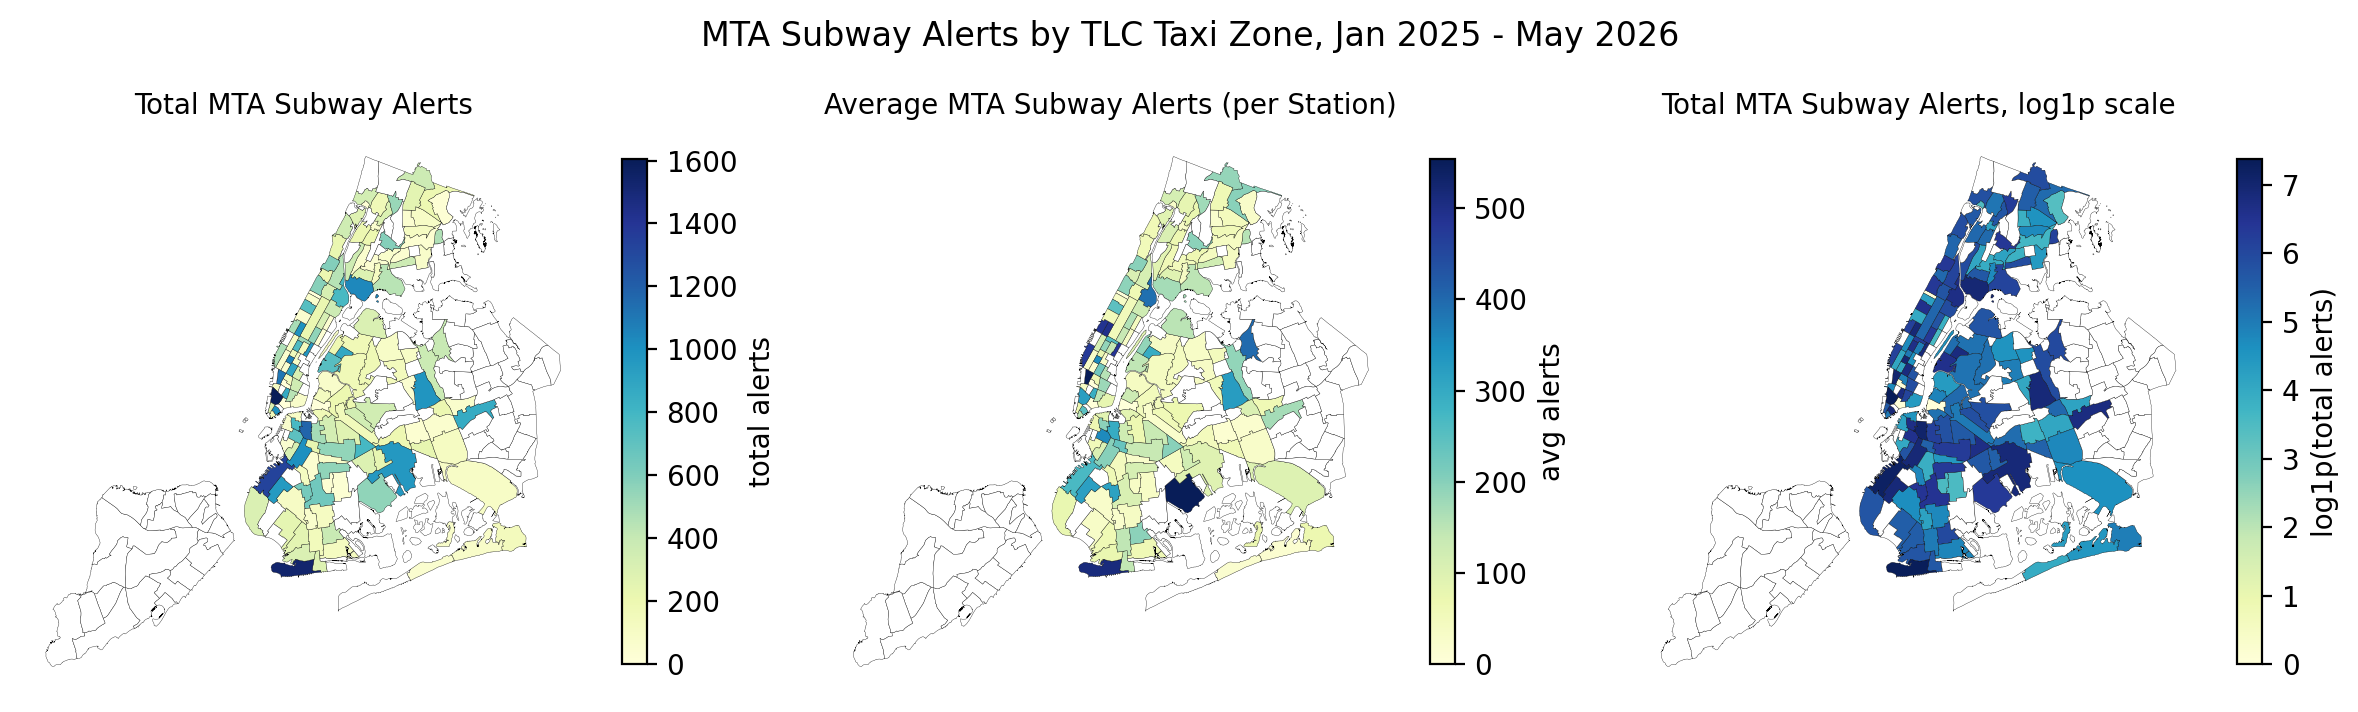

In [14]:
# Average alerts per mapped subway station in each TLC taxi zone (take into account n_stations)
zone_metrics_geo["avg_alerts_per_station"] = np.where(
    (zone_metrics_geo["n_stations"].notna()) & (zone_metrics_geo["n_stations"] > 0),
    zone_metrics_geo["total_alerts"] / zone_metrics_geo["n_stations"],
    np.nan
)

# Maps to show spatial distribution of summed and average `n_alerts` between 2025 Jan - 2026 May
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=200)

alert_map_specs = [
    ("total_alerts", "Total MTA Subway Alerts", "total alerts", "YlGnBu"),
    ("avg_alerts_per_station", "Average MTA Subway Alerts (per Station)", "avg alerts", "YlGnBu"),
    ("log1p_total_alerts", "Total MTA Subway Alerts, log1p scale", "log1p(total alerts)", "YlGnBu")
]

for ax, (col, title, legend_label, cmap) in zip(axes, alert_map_specs):
    zone_metrics_geo.plot(
        ax=ax,
        column=col,
        cmap=cmap,
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": legend_label}
    )
    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle("MTA Subway Alerts by TLC Taxi Zone, Jan 2025 - May 2026", fontsize=12, y=0.9)
plt.tight_layout()
plt.show()

We show both total and average MTA alerts per zone to consider `n_stations`. There are a zones with very high average alerts which we will investigate: 

In [15]:
sdf_alerts_which_station = spark.read.parquet(f"{features_dir}/alerts_which_station")

# What are the top 10 subway station complexes with the highest total alerts over 2025 Jan - 2026 May?
(
    sdf_alerts_which_station
    .groupBy("station_complex_id", "station_complex", "PULocationID")
    .agg(
        F.countDistinct("event_id").alias("n_unique_alert_events"),
        F.count("*").alias("n_station_alert_rows"),
        F.sum("disruption_severity").alias("total_disruption_severity")
    )
    .orderBy(F.desc("n_unique_alert_events"))
    .show(8, truncate=False)
)

# What are the top 10 zones with the highest total alerts over 2025 Jan - 2026 May?
(
    sdf_tlc_hourly
    .groupBy("PULocationID", "taxi_zone", "borough")
    .agg(
        F.sum("n_alerts").alias("total_alerts"),
        F.sum("disruption_severity").alias("total_disruption_severity"),
        F.max("n_stations").alias("n_stations")
    )
    .orderBy(F.desc("total_alerts"))
    .show(8, truncate=False)
)

# What are the top 10 zones with the highest average alerts per station over 2025 Jan - 2026 May?
(
    sdf_tlc_hourly
    .groupBy("PULocationID", "taxi_zone", "borough")
    .agg(
        F.sum("n_alerts").alias("total_alerts"),
        F.sum("disruption_severity").alias("total_disruption_severity"),
        F.max("n_stations").alias("n_stations")
    )
    .withColumn(
        "avg_alerts_per_station",
        F.col("total_alerts") / F.col("n_stations")
    )
    .orderBy(F.desc("avg_alerts_per_station"))
    .show(8, truncate=False)
)

+------------------+--------------------------------------------+------------+---------------------+--------------------+-------------------------+
|station_complex_id|station_complex                             |PULocationID|n_unique_alert_events|n_station_alert_rows|total_disruption_severity|
+------------------+--------------------------------------------+------------+---------------------+--------------------+-------------------------+
|58                |Coney Island-Stillwell Av (D,F,N,Q)         |55          |1149                 |2186                |2941                     |
|167               |W 4 St-Wash Sq (A,C,E,B,D,F,M)              |249         |881                  |1557                |2367                     |
|610               |Grand Central-42 St (4,5,6,7,S)             |162         |803                  |1422                |2093                     |
|614               |59 St-Columbus Circle (1,A,C,B,D)           |142         |791                  |1442        

- Stations with highest total alerts in time frame: Coney Island-Stillwell Av (zone 55), W 4 St-Wash Sq (zone 249), Grand Central-42 St (zone 162)
- Zones with highest total alerts in time frame: zone 231, zone 55, zone 228 
- Zones with highest average alerts per station in time frame: zone 249, zone 39, zone 55

A quick google search tells us that the stations with highest total alerts are largely major transfer complexes wth multiple subway lines, meaning any disruption along these lines could affect these stations. Overall, major transfer subway stations is prominent in ranking of stations with high average disruptions. 

For zones with highest total alerts, we can expect possibly heavier pressure on the transport system in the zone, as no. stations could also be related to demand. 

#### Average MTA Subway Alert Disruption Severity by TLC Taxi Zone, Jan 2025 - May 2026
We calculate the average disruption_severity for each zone / station, over the given time frame. 

Note, the same event_id will only be counted once within the same hour, even if it had multiple alert updates during the hour. However, if the same event_id has an alert update in another hour, it will be counted again. This adjusts for sustained effect from certain high-impact events, without overrepresenting events which have updates more frequently than others. This comes from how `n_alerts` is constructed per `(PULocation, hour)`.

/Users/hannahluo/miniconda3/envs/mast30034/lib/python3.10/site-packages/shapely/set_operations.py:553: RuntimeWarning: invalid value encountered in unary_union
  return lib.unary_union(collections, **kwargs)


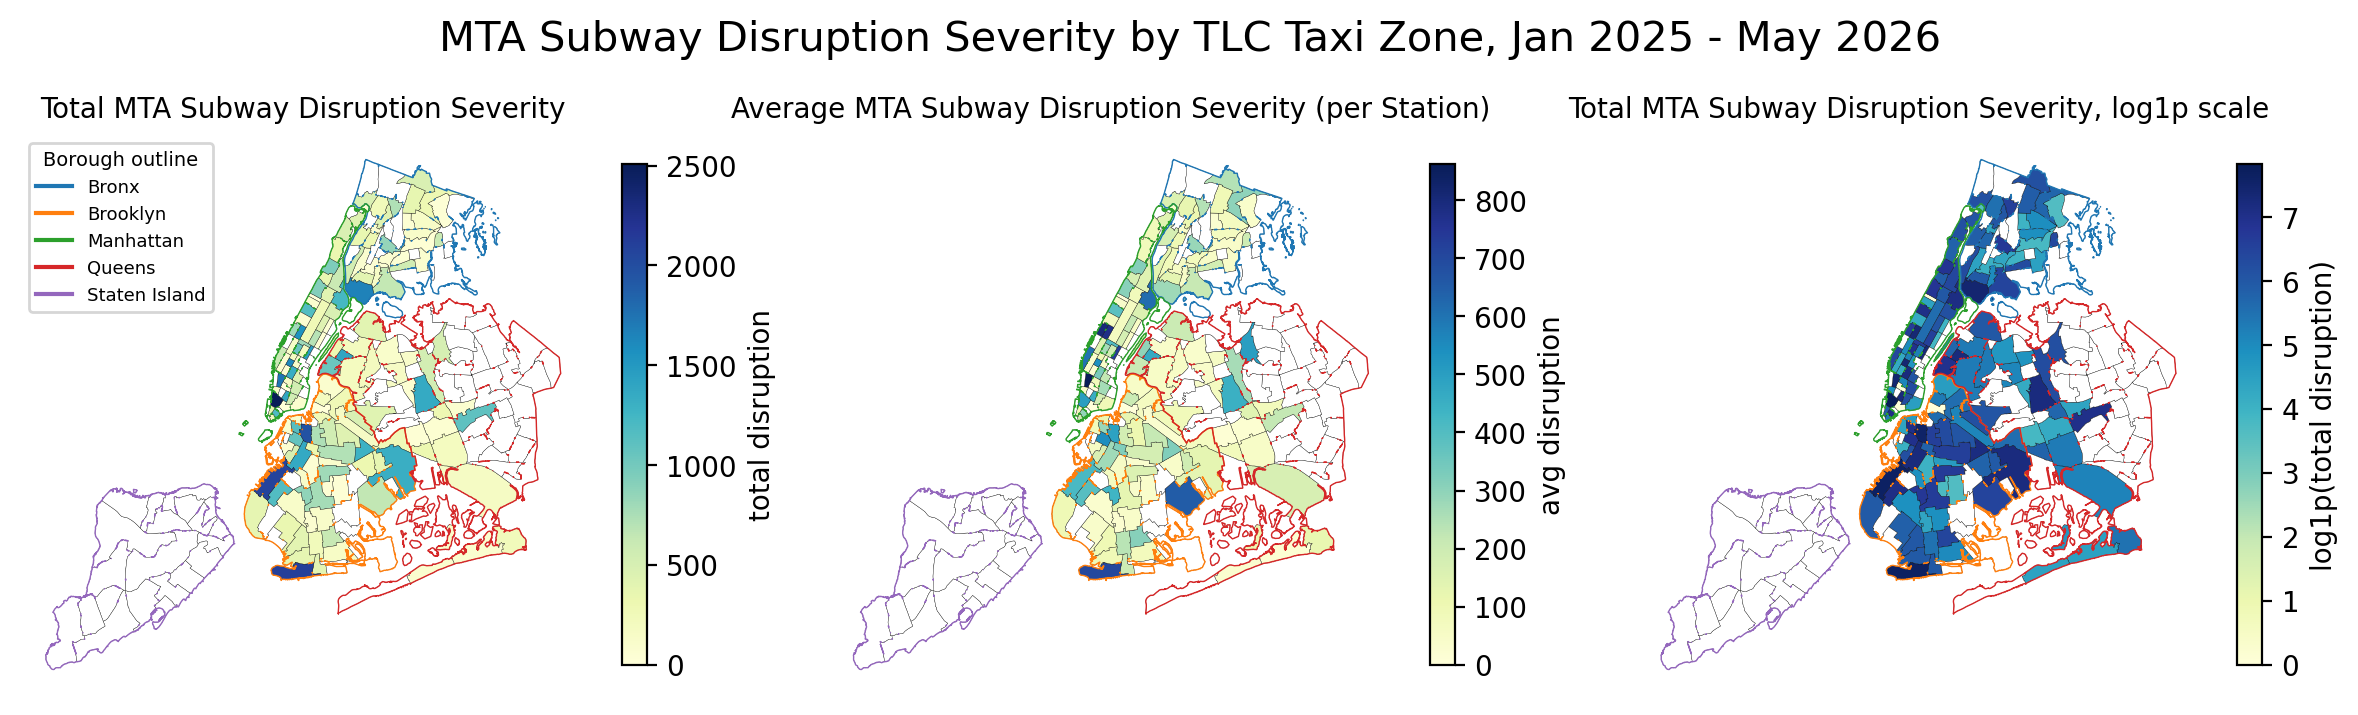

In [16]:
# Average disruption per mapped subway station in each TLC taxi zone
zone_metrics_geo["avg_disruption_per_station"] = np.where(
    (zone_metrics_geo["n_stations"].notna()) & (zone_metrics_geo["n_stations"] > 0),
    zone_metrics_geo["total_disruption"] / zone_metrics_geo["n_stations"],
    np.nan
)

# Borough outline colours
borough_shapes = zones[zones["borough"].isin(borough_order)].dissolve(by="borough")

borough_handles = [
    Line2D([0], [0], color=borough_palette[b], linewidth=1.5, label=b)
    for b in borough_order
    if b in borough_shapes.index
]

# Maps to show spatial distribution of summed and average disruption severity
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=200)

alert_map_specs = [
    ("total_disruption", "Total MTA Subway Disruption Severity", "total disruption", "YlGnBu"),
    ("avg_disruption_per_station", "Average MTA Subway Disruption Severity (per Station)", "avg disruption", "YlGnBu"),
    ("log1p_total_disruption", "Total MTA Subway Disruption Severity, log1p scale", "log1p(total disruption)", "YlGnBu"),
]

for i, (ax, (col, title, legend_label, cmap)) in enumerate(zip(axes, alert_map_specs)):
    zone_metrics_geo.plot(
        ax=ax,
        column=col,
        cmap=cmap,
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": legend_label}
    )

    for borough, row in borough_shapes.iterrows():
        gpd.GeoSeries([row.geometry], crs=zones.crs).boundary.plot(
            ax=ax,
            color=borough_palette[borough],
            linewidth=0.5
        )

    if i == 0:
        ax.legend(
            handles=borough_handles,
            title="Borough outline",
            loc="upper left",
            fontsize=6.5,
            title_fontsize=7,
            frameon=True
        )

    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle("MTA Subway Disruption Severity by TLC Taxi Zone, Jan 2025 - May 2026", fontsize=15, y=0.9)
plt.tight_layout()
plt.show()

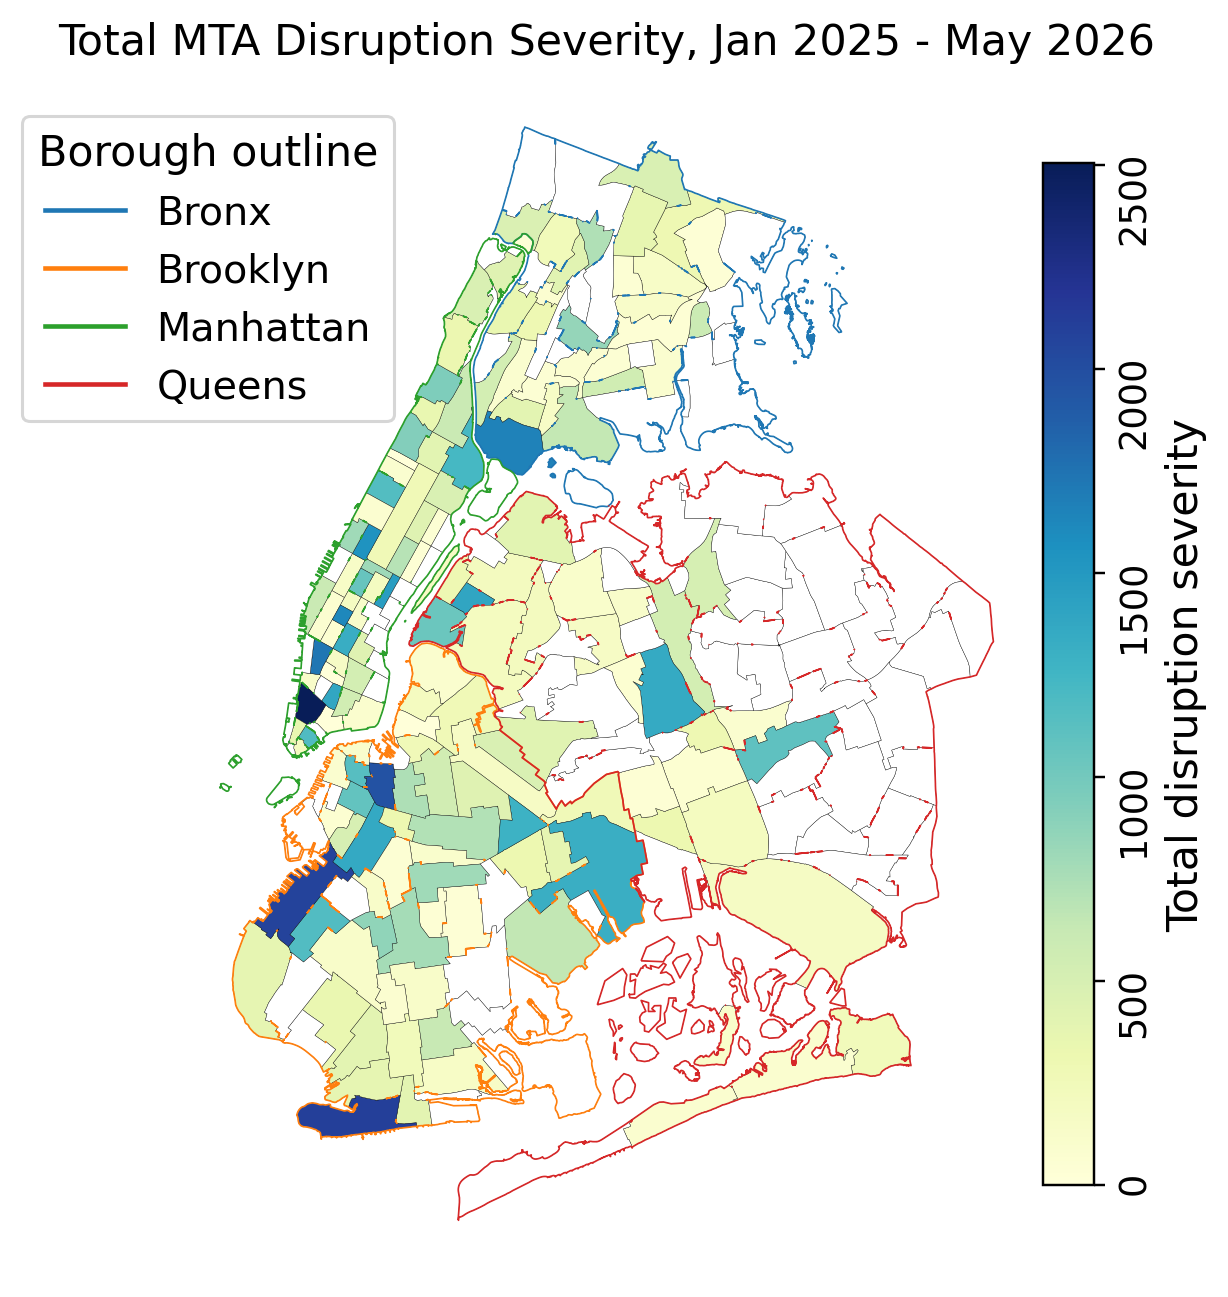

In [17]:
# Enlarged selected plot specifically for the report, excluding Staten Island
plot_geo = zone_metrics_geo[zone_metrics_geo["borough"].isin(borough_order[:4])].copy()
plot_borough_shapes = borough_shapes.loc[
    borough_shapes.index.intersection(borough_order[:4])
]

plot_borough_handles = [
    Line2D([0], [0], color=borough_palette[b], linewidth=1.5, label=b)
    for b in borough_order[:4]
    if b in plot_borough_shapes.index
]

fig, ax = plt.subplots(figsize=(5.6, 6), dpi=220)

plot_geo.plot(
    ax=ax,
    column="total_disruption",
    cmap="YlGnBu",
    edgecolor="black",
    linewidth=0.12,
    legend=True,
    missing_kwds=missing_kwds,
    legend_kwds={
        "shrink": 0.85,
        "label": "Total disruption severity",
        "pad": 0.01
    }
)

# Colour bar font sizes
cbar_ax = fig.axes[-1]
cbar_ax.set_ylabel("Total disruption severity", fontsize=14)
cbar_ax.tick_params(labelsize=12, rotation=90)

for borough, row in plot_borough_shapes.iterrows():
    gpd.GeoSeries([row.geometry], crs=zones.crs).boundary.plot(
        ax=ax,
        color=borough_palette[borough],
        linewidth=0.55
    )

ax.legend(
    handles=plot_borough_handles,
    title="Borough outline",
    loc="upper left",
    bbox_to_anchor=(-0.21, 0.98),
    fontsize=13,
    title_fontsize=14,
    frameon=True
)

ax.set_title("Total MTA Disruption Severity, Jan 2025 - May 2026", fontsize=14)
ax.axis("off")

plt.tight_layout()
plt.show()

Investigate the top zones / subway stations with highest total disruption:

In [18]:
sdf_alerts_which_station = spark.read.parquet(f"{features_dir}/alerts_which_station")

# Collapse to one row per station-hour-event, consistent with zone-hour aggregation
sdf_station_alert_events = (
    sdf_alerts_which_station
    .groupBy("station_complex_id", "station_complex", "PULocationID", "hour", "event_id")
    .agg(F.max("disruption_severity").alias("event_disruption_severity"))
)

# What are the top 10 subway station complexes with the highest total disruption over 2025 Jan - 2026 May?
(
    sdf_station_alert_events
    .groupBy("station_complex_id", "station_complex", "PULocationID")
    .agg(
        F.countDistinct("event_id").alias("n_unique_alert_events"),
        F.count("*").alias("n_alert_event_hours"),
        F.sum("event_disruption_severity").alias("total_disruption_severity")
    )
    .orderBy(F.desc("total_disruption_severity"))
    .show(8, truncate=False)
)

# What are the top 10 zones with the highest total disruption over 2025 Jan - 2026 May?
(
    sdf_tlc_hourly
    .groupBy("PULocationID", "taxi_zone", "borough")
    .agg(
        F.sum("n_alerts").alias("total_alerts"),
        F.sum("disruption_severity").alias("total_disruption_severity"),
        F.max("n_stations").alias("n_stations"),
        F.sum("ridership").alias("total_ridership")
    )
    .orderBy(F.desc("total_disruption_severity"))
    .show(8, truncate=False)
)

# What are the top 10 zones with the highest average disruption per station over 2025 Jan - 2026 May?
(
    sdf_tlc_hourly
    .groupBy("PULocationID", "taxi_zone", "borough")
    .agg(
        F.sum("n_alerts").alias("total_alerts"),
        F.sum("disruption_severity").alias("total_disruption_severity"),
        F.max("n_stations").alias("n_stations"),
        F.sum("ridership").alias("total_ridership")
    )
    .withColumn(
        "avg_disruption_per_station",
        F.col("total_disruption_severity") / F.col("n_stations")
    )
    .orderBy(F.desc("avg_disruption_per_station"))
    .show(8, truncate=False)
)

+------------------+-----------------------------------+------------+---------------------+-------------------+-------------------------+
|station_complex_id|station_complex                    |PULocationID|n_unique_alert_events|n_alert_event_hours|total_disruption_severity|
+------------------+-----------------------------------+------------+---------------------+-------------------+-------------------------+
|58                |Coney Island-Stillwell Av (D,F,N,Q)|55          |1149                 |1434               |2003                     |
|167               |W 4 St-Wash Sq (A,C,E,B,D,F,M)     |249         |881                  |1054               |1655                     |
|614               |59 St-Columbus Circle (1,A,C,B,D)  |142         |791                  |955                |1507                     |
|610               |Grand Central-42 St (4,5,6,7,S)    |162         |803                  |961                |1464                     |
|261               |Forest Hills-7

#### Average FHVHV wait time by TLC Taxi Zone, Jan 2025 - May 2026
We calculate the average fhvhv wait time for each zone / station, over the given time frame and plot these spatially.

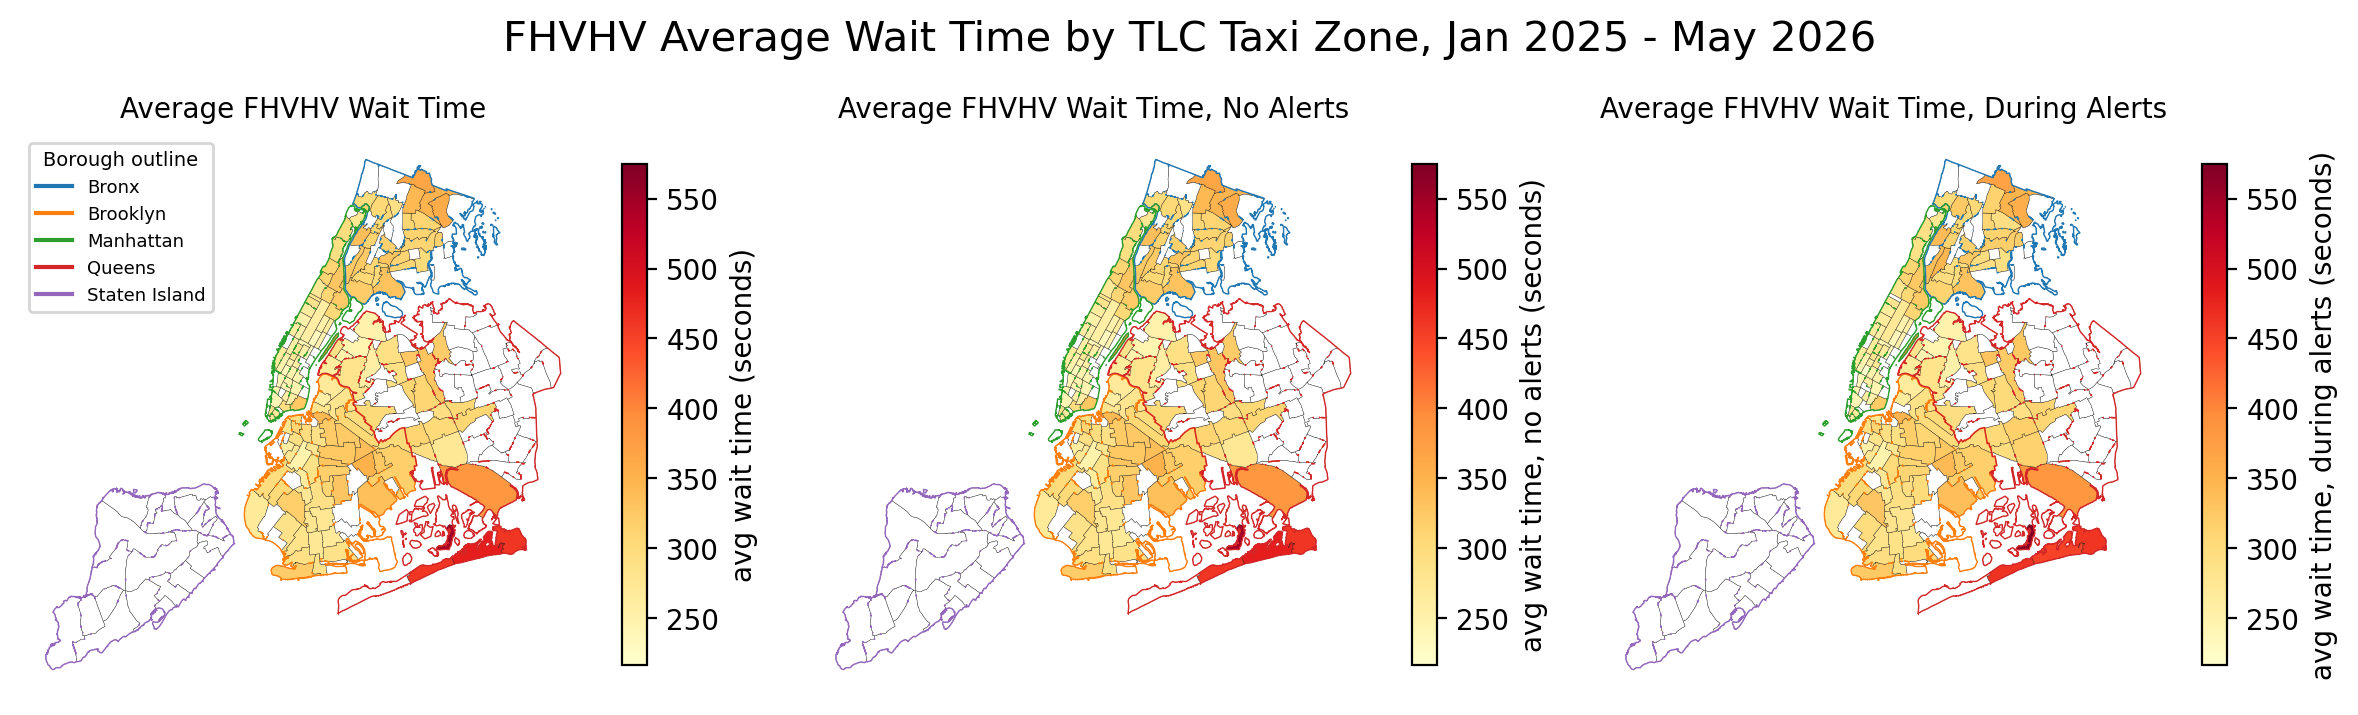

In [19]:
# Average FHVHV wait time by TLC taxi zone
wait_time_pd = (
    sdf_tlc_hourly
    .groupBy("PULocationID")
    .agg(
        F.avg("avg_wait_time_fhvhv").alias("avg_wait_time"),
        F.avg(F.when(F.col("n_alerts") == 0, F.col("avg_wait_time_fhvhv"))).alias("avg_wait_time_no_alert"),
        F.avg(F.when(F.col("n_alerts") > 0, F.col("avg_wait_time_fhvhv"))).alias("avg_wait_time_alert"),
    )
    .toPandas()
    .rename(columns={"PULocationID": "LocationID"})
)

wait_time_geo = zones.merge(
    wait_time_pd,
    on="LocationID",
    how="left"
)

# Same colour scale across all three maps for direct comparison
wait_cols = ["avg_wait_time", "avg_wait_time_no_alert", "avg_wait_time_alert"]
wait_vmin = wait_time_geo[wait_cols].min().min()
wait_vmax = wait_time_geo[wait_cols].max().max()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), dpi=200)

wait_time_map_specs = [
    ("avg_wait_time", "Average FHVHV Wait Time", "avg wait time (seconds)"),
    ("avg_wait_time_no_alert", "Average FHVHV Wait Time, No Alerts", "avg wait time, no alerts (seconds)"),
    ("avg_wait_time_alert", "Average FHVHV Wait Time, During Alerts", "avg wait time, during alerts (seconds)"),
]

for i, (ax, (col, title, legend_label)) in enumerate(zip(axes, wait_time_map_specs)):
    wait_time_geo.plot(
        ax=ax,
        column=col,
        cmap="YlOrRd",
        edgecolor="black",
        linewidth=0.12,
        legend=True,
        vmin=wait_vmin,
        vmax=wait_vmax,
        missing_kwds=missing_kwds,
        legend_kwds={"shrink": 0.65, "label": legend_label}
    )

    for borough, row in borough_shapes.iterrows():
        gpd.GeoSeries([row.geometry], crs=zones.crs).boundary.plot(
            ax=ax,
            color=borough_palette[borough],
            linewidth=0.5
        )

    if i == 0:
        ax.legend(
            handles=borough_handles,
            title="Borough outline",
            loc="upper left",
            fontsize=6.5,
            title_fontsize=7,
            frameon=True
        )

    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle("FHVHV Average Wait Time by TLC Taxi Zone, Jan 2025 - May 2026", fontsize=15, y=0.9)
plt.tight_layout()
plt.show()

## Temporal visualisations
All timestamps have been preprocessed to local time in `02_preprocess_data`, so we can conduct interpretablehour-of-day and day-of-week analysis.

In [ ]:
# Add temporal features once to reuse for all temporal plots
sdf_temporal = (
    sdf_tlc_hourly
    .withColumn("month", F.date_trunc("month", "hour"))
    .withColumn("hour_of_day", F.hour("hour"))
    .withColumn("day_of_week", F.date_format("hour", "E")) # extracts abbreviated weekday names from timestamp stored in `hour`
    .withColumn("avg_wait_time_fhvhv_no_alert", F.when(F.col("n_alerts") == 0, F.col("avg_wait_time_fhvhv")) # avg wait time for rows without alerts
)
)

# Specify day order for days of week
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

### Temporal context
First, visualise the timeframe within which we analyse. The temporal desnity of data is constant over the timeframe 2025 Jan - 2026 May as we have preprocessed to hourly granularity.

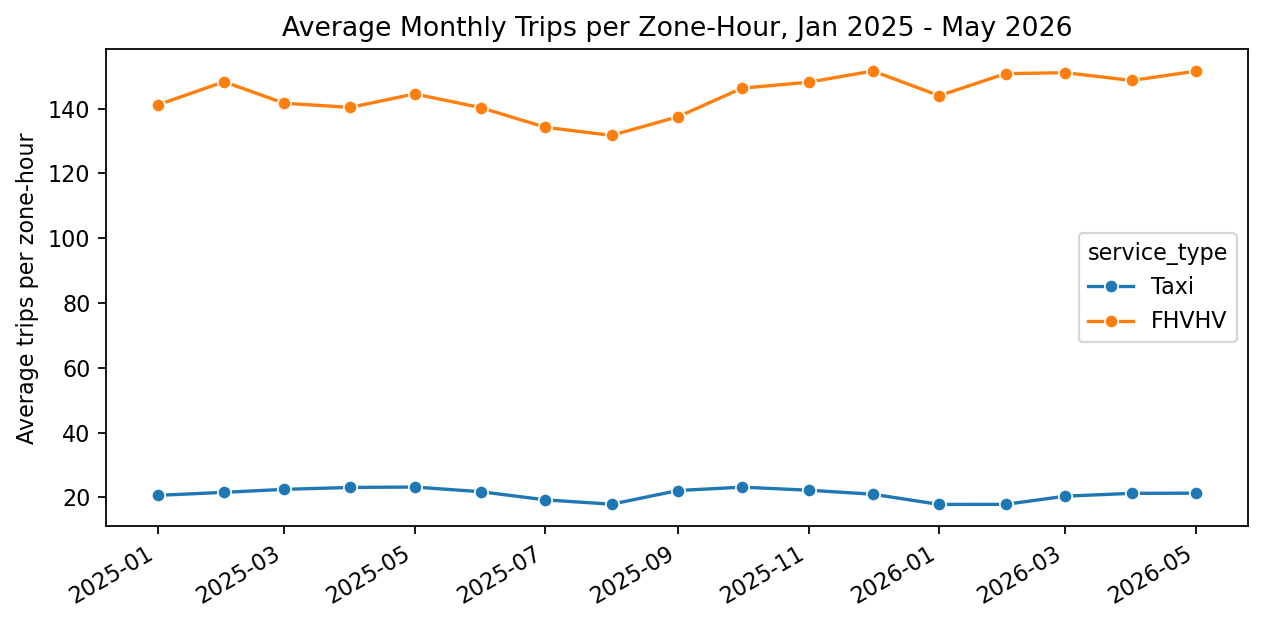

In [ ]:
# Monthly average
monthly_trips_pd = (
    sdf_temporal
    .groupBy("month")
    .agg(
        F.avg("n_trips_taxi").alias("Taxi"),
        F.avg("n_trips_fhvhv").alias("FHVHV")
    )
    .orderBy("month")
    .toPandas()
)

# Convert wide dataframe to long (by specifying taxi and fhvhv rows for each month)
monthly_trips_long = monthly_trips_pd.melt(
    id_vars="month",
    value_vars=["Taxi", "FHVHV"],
    var_name="service_type",
    value_name="avg_trips_per_zone_hour"
)

plt.figure(figsize=(8, 4), dpi=160)

sns.lineplot(
    data=monthly_trips_long,
    x="month",
    y="avg_trips_per_zone_hour",
    hue="service_type",
    marker="o"
)

plt.title("Average Monthly Trips per Zone-Hour, Jan 2025 - May 2026")
plt.xlabel("")
plt.ylabel("Average trips per zone-hour")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

The temporal context plot is a bit too broad, and we can't necessarily see much repeating pattern due to the time frame being limited to 17 months. Nevertheless, we can see that `n_trips_taxi` dipped slightly in 2025 Aug, 2026 Jan and Feb. For `n_trips_fhvhv`, there is more variation across the months, with the minimum over 17 months being 2025 Aug, which matches with the taxi's minimum. However, we don't have 2026 Aug data to compare with here, so we cannot state conclusions about seasonality. 

### Hour-of-Day and Day-of-Week profiles 
For `n_trips`, `n_alerts`, `ridership`, we define the borough average as being the average zone value of a borough. 
- e.g. average `n_trips_taxi` of Manhattan at 8am = 100, means the average Manhattan zone has 100 taxi trips at 8am, NOT that Manhattan the entire borough on average has 100 taxi trips at 8am. 

In [22]:
def plot_hour_day_profiles(metric, title, ylabel):
    """ 
    plots hour-of-day and day-of-week line plots as facets for given metric (e.g. n_trips_taxi), title of plot, and ylabel of plot
    """
    # Hour of day 
    hourly_pd = (
        sdf_temporal
        .groupBy("borough", "hour_of_day") # group all rows by borough and hour-of-day
        .agg(F.avg(metric).alias(f"avg_{metric}")) # average the metric within each group
        .toPandas()
    )

    # Day of week 
    dow_pd = (
        sdf_temporal
        .groupBy("borough", "day_of_week")  # group all rows by borough and day-of-week
        .agg(F.avg(metric).alias(f"avg_{metric}")) # average the metric within each group
        .toPandas()
    )

    dow_pd["day_of_week"] = pd.Categorical(
        dow_pd["day_of_week"],
        categories=day_order,
        ordered=True
    )
    dow_pd = dow_pd.sort_values(["borough", "day_of_week"])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=160)

    sns.lineplot(
        data=hourly_pd,
        x="hour_of_day",
        y=f"avg_{metric}",
        hue="borough",
        hue_order=borough_order[:4],
        palette=borough_palette,
        marker="o",
        ax=axes[0]
    )
    axes[0].set_title("By Hour of Day")
    axes[0].set_xlabel("Hour of day")
    axes[0].set_ylabel(ylabel)
    axes[0].grid(axis="y", alpha=0.2)

    axes[0].legend(
        title="borough",
        fontsize=8,
        title_fontsize=8,
        loc="best",
        frameon=True,
        framealpha=0.85,
        borderpad=0.3,
        labelspacing=0.3,
        handlelength=1.6
    )
    sns.lineplot(
        data=dow_pd,
        x="day_of_week",
        y=f"avg_{metric}",
        hue="borough",
        hue_order=borough_order[:4],
        palette=borough_palette,
        marker="o",
        ax=axes[1], 
        legend=False
    )
    axes[1].set_title("By Day of Week")
    axes[1].set_xlabel("")
    axes[1].set_ylabel(ylabel)
    axes[1].grid(axis="y", alpha=0.2)

    fig.suptitle(title, fontsize=15, y=0.98)
    plt.tight_layout()
    plt.show()

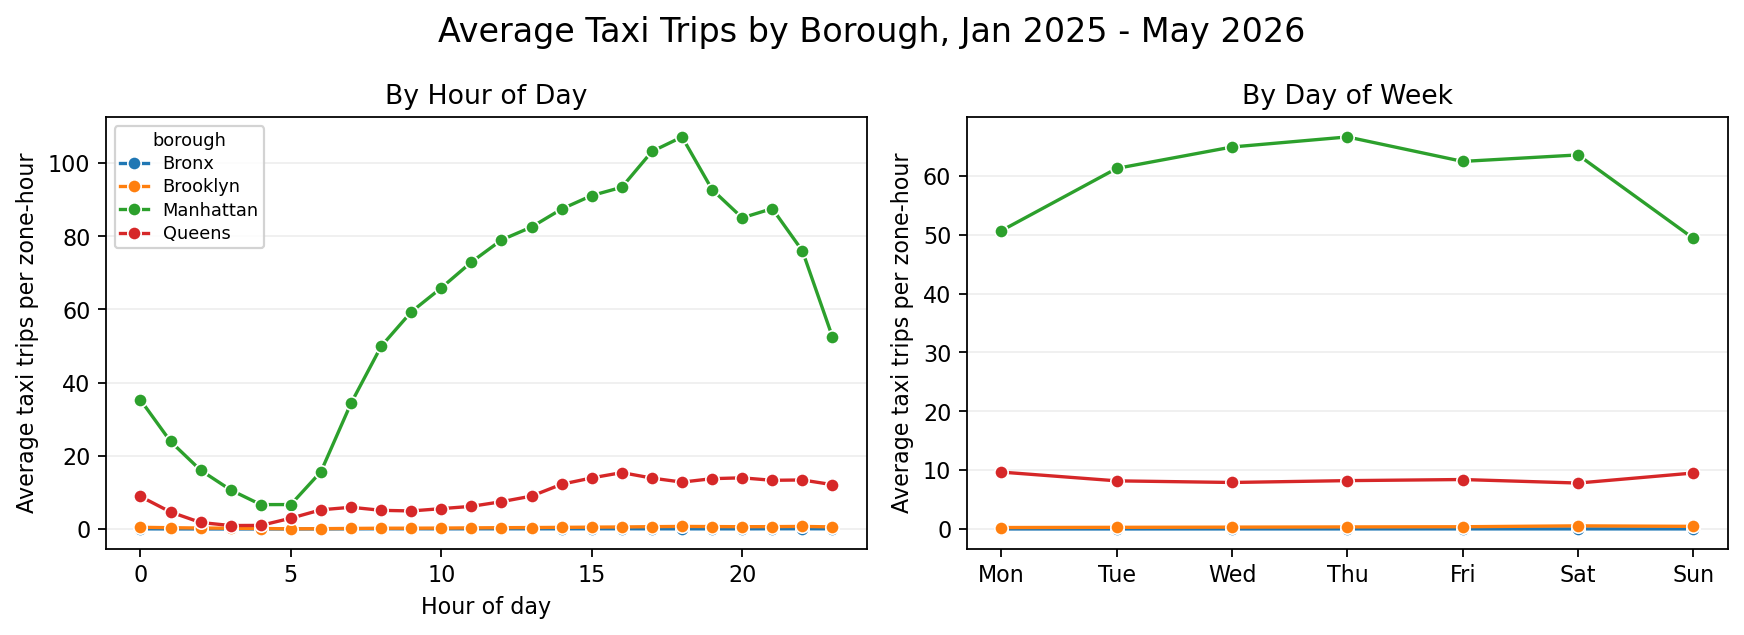

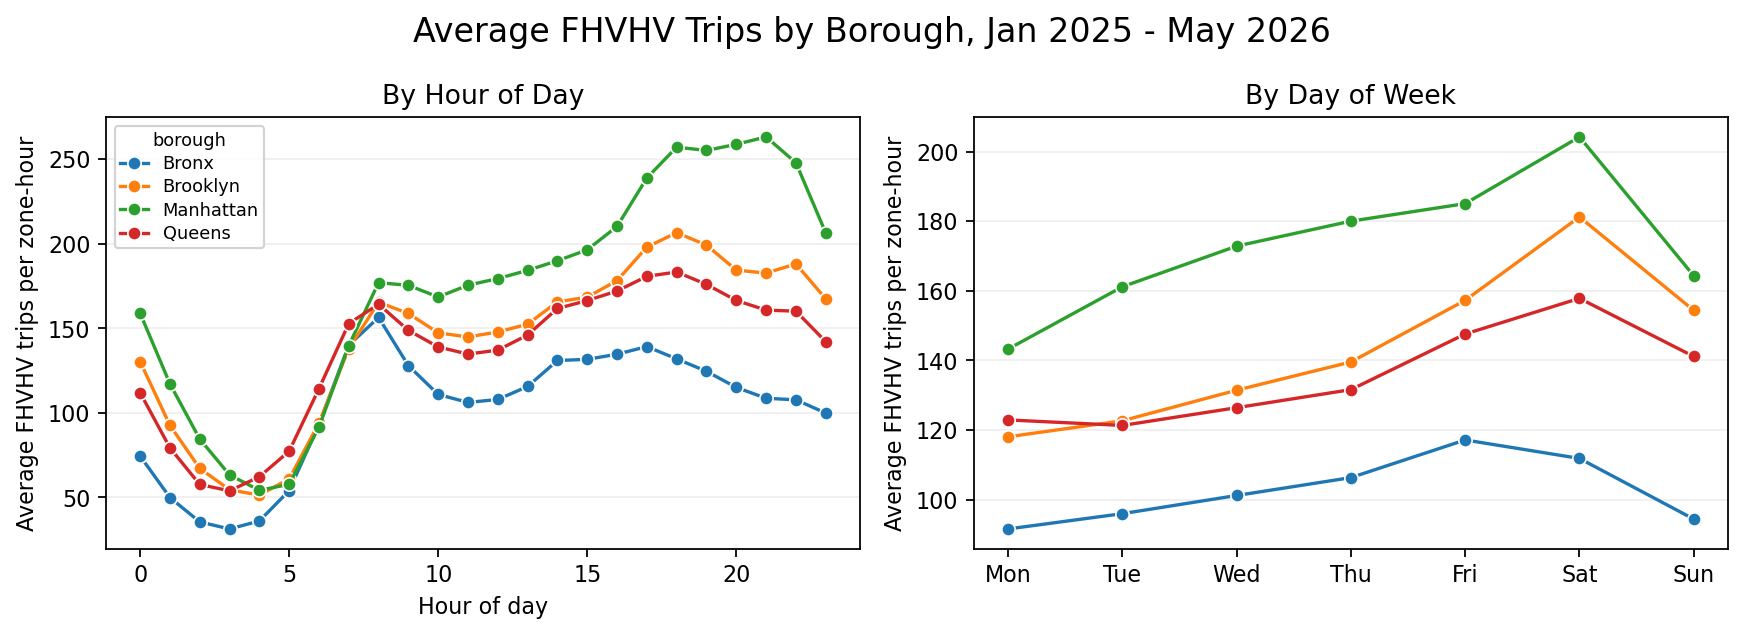

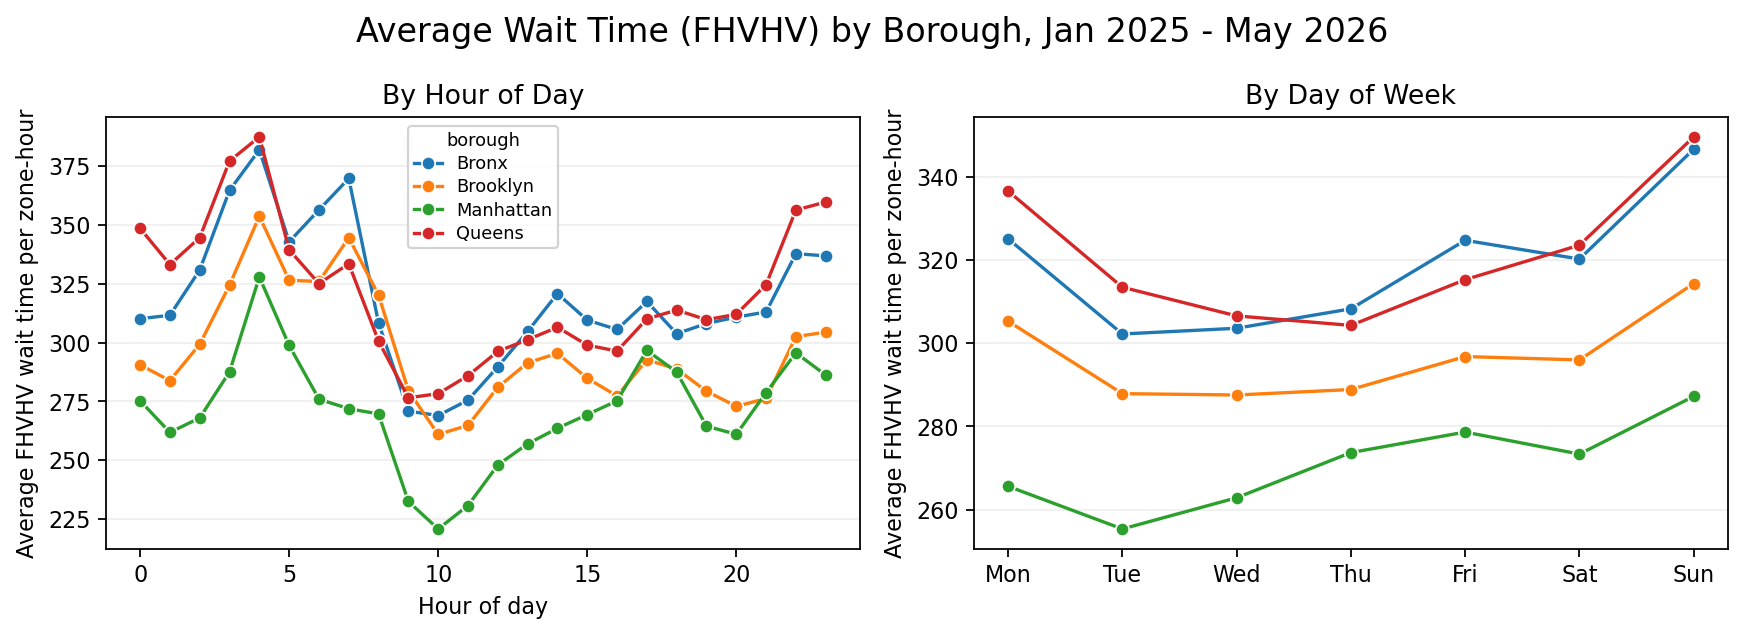

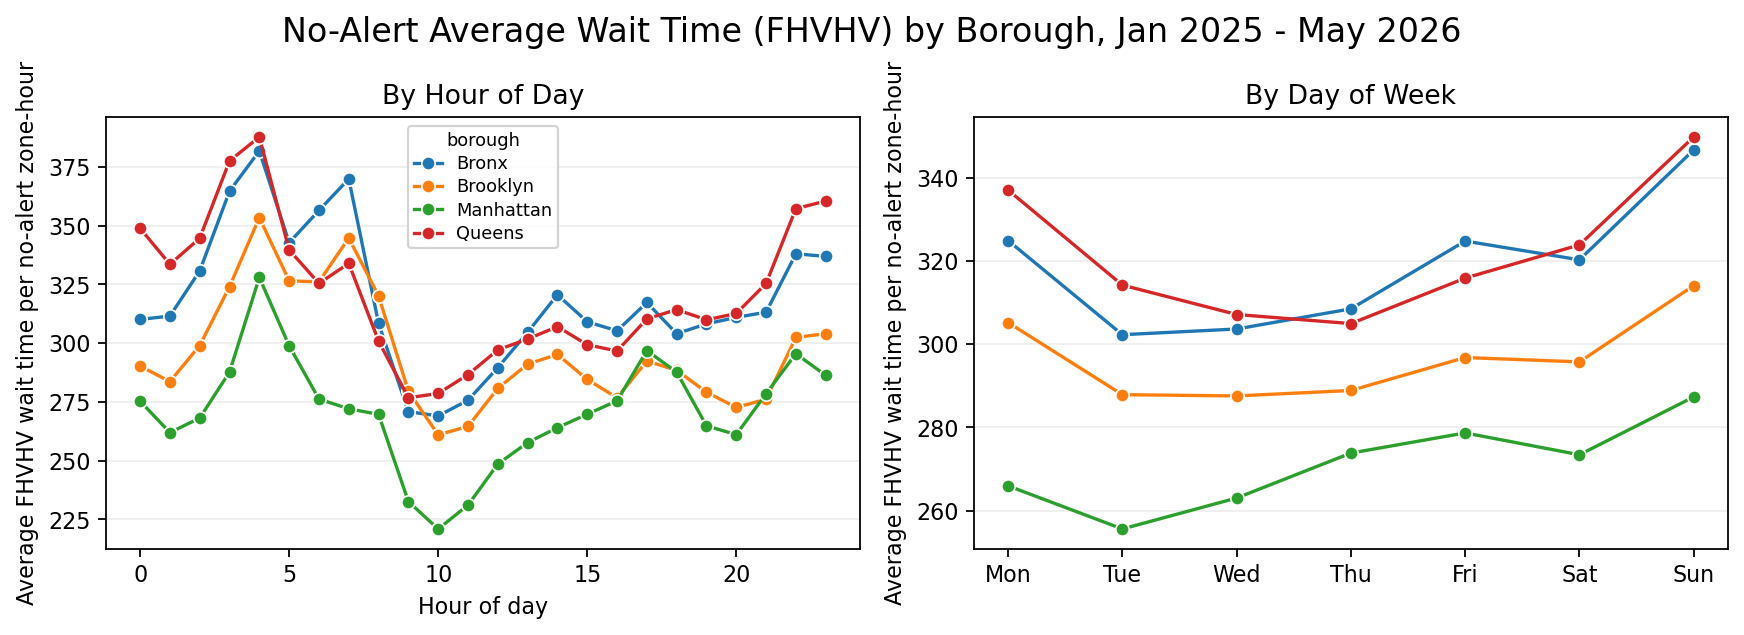

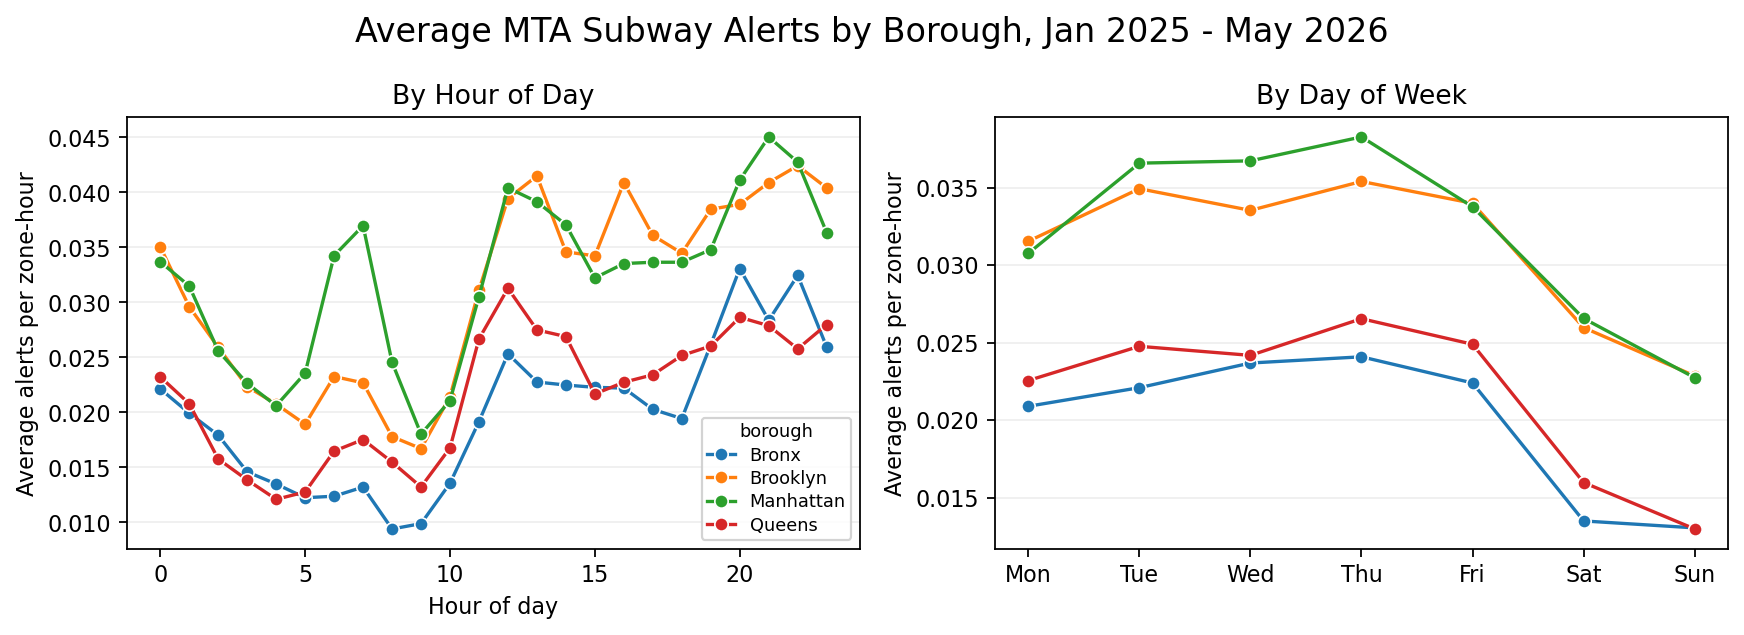

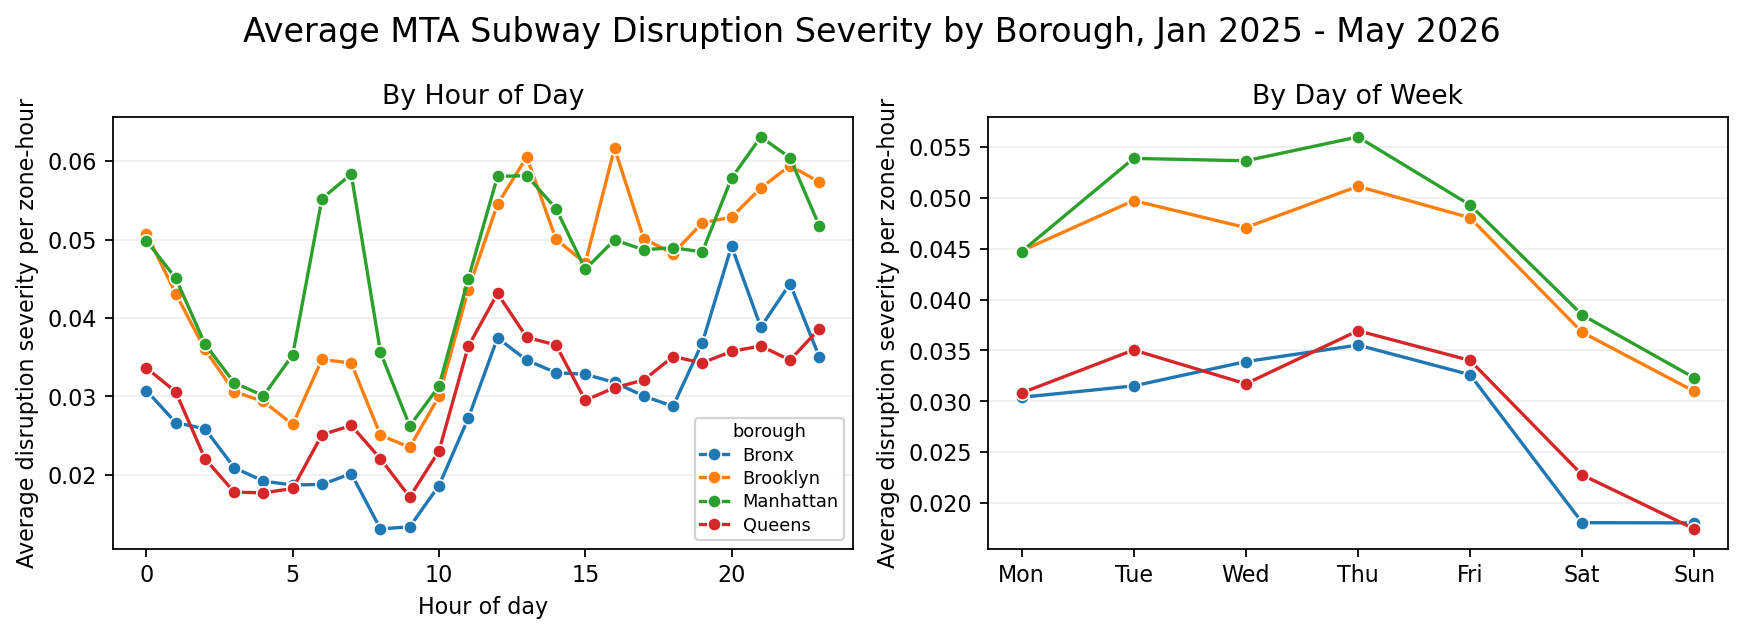

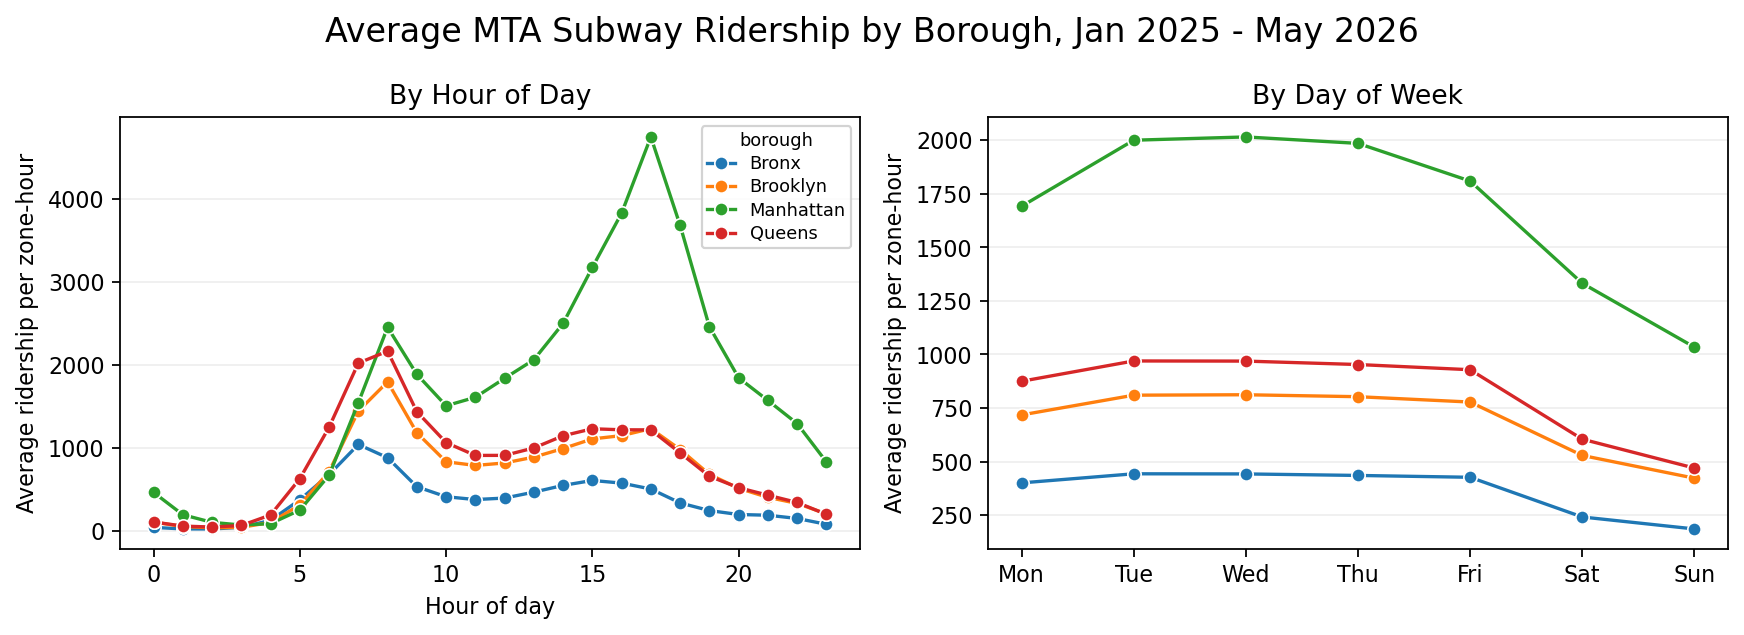

In [23]:
# Plot hour-of-day and day-of-week profiles for attributes of interest 
plot_hour_day_profiles(
    "n_trips_taxi",
    "Average Taxi Trips by Borough, Jan 2025 - May 2026",
    "Average taxi trips per zone-hour"
)

plot_hour_day_profiles(
    "n_trips_fhvhv",
    "Average FHVHV Trips by Borough, Jan 2025 - May 2026",
    "Average FHVHV trips per zone-hour"
)

plot_hour_day_profiles(
    "avg_wait_time_fhvhv", 
    "Average Wait Time (FHVHV) by Borough, Jan 2025 - May 2026", 
    "Average FHVHV wait time per zone-hour"
)

plot_hour_day_profiles(
    "avg_wait_time_fhvhv_no_alert",
    "No-Alert Average Wait Time (FHVHV) by Borough, Jan 2025 - May 2026",
    "Average FHVHV wait time per no-alert zone-hour"
)

plot_hour_day_profiles(
    "n_alerts",
    "Average MTA Subway Alerts by Borough, Jan 2025 - May 2026",
    "Average alerts per zone-hour"
)

plot_hour_day_profiles(
    "disruption_severity",
    "Average MTA Subway Disruption Severity by Borough, Jan 2025 - May 2026",
    "Average disruption severity per zone-hour"
)

plot_hour_day_profiles(
    "ridership",
    "Average MTA Subway Ridership by Borough, Jan 2025 - May 2026",
    "Average ridership per zone-hour"
)

- average taxi trips by borough is very different between boroughs, due to the nature of the taxis concentrating in manhattan. bronx and brooklyn and relatively close to zero due to low trip counts. queens has a rise in trips around midday/evening (1-11pm), for which one might hypothesise is a popular time for plane arrivals. manhattan has a massive spike in trips during the day (7am-12am), as expected. the by day of week is very constant for boroughs other than manhattan, and manhattan has slightly more trips between tuesday and saturday. 

- average fhvhv trips across boroughs follow a very similar pattern to each other, just at different y-values (like kinda translated in the y-axis). this could suggest that the dispatching of fhvhv services to each borough is appears more spatially distributed than taxi pickups, and there's no clear sign of manhattan dominating the dispatched services (other than that it naturally has more demand). by day of the week shows that fhvhv trips peak on the weekends. perhaps weekend travellers prefer fhvhv, considering the lack of visually significant increase for taxi trips. 

- average fhvhv wait time for hour of day is more sporadic across the boroughs, although it is clear that early morning (3-5am), there is a spike in waiting time across all boroughs. The fhvhv waiting time is at a minimum in the late morning (9-11am), consistently across all boroughs. Overall, Manhattan sees a much lower waiting time, and Queens the highest. By day of week, wait time is minimised on Tuesday for Manhattan and Bronx, minimised on Thursday for Queens, and Brooklyn has a plateau of lower wait times between Tuesday-Thursday. All boroughs have wait time increase on weekends compared to weekdays. 

- average mta subway alerts is way more sporadic and less obvious with its trends, although there is a decrease shared between all boroughs between 12-4am approximately. there is a massive spike for manhattan at 5-7am where other boroughs experience a smaller inrease on average. then from 9am-12pm, the average increases steadily for all boroughs, then fluctuates with non-uniform patterns for the rest of the day. for day of the week, we can see sat-sun with much lower averages, and weekday troughs are particularly clear for Manhattan and Brooklyn.

- average mta subway ridership for hour of day spikes across all boroughs at morning peak, between 6-9am. manhattan then has a massive peak in ridership approximately between 3-7pm, which we might interpret as a combination of business district off-work peak hour, and people going to manhattan for its shopping and entertainment districts. by day of week, the trend is again simlar to that of alerts. for boroughs other than manhattan, the ridership is particularly constant across weekdays, while manhattan has slightly higher ridership for midweek tue-thu. 

### Hour-of-Week profiles

In [24]:
# Add hour-of-week index: Mon 00:00 = 0, ..., Sun 23:00 = 167
sdf_temporal = sdf_temporal.withColumn(
    "hour_of_week",
    ((F.dayofweek("hour") + 5) % 7) * 24 + F.hour("hour")
)

In [25]:
def plot_hour_of_week(metric, title, ylabel):
    """ 
    plots hour-of-week line plots given metric, title of plot, and ylabel of plot
    """

    hour_week_pd = (
        sdf_temporal
        .groupBy("borough", "hour_of_week")
        .agg(F.avg(metric).alias(f"avg_{metric}"))
        .toPandas()
    )

    plt.figure(figsize=(12, 3.8), dpi=160)

    ax = sns.lineplot(
        data=hour_week_pd,
        x="hour_of_week",
        y=f"avg_{metric}",
        hue="borough",
        hue_order=borough_order[:4],
        palette=borough_palette,
        linewidth=2.2
    )

    day_ticks = [i * 24 for i in range(7)]
    ax.set_xticks(day_ticks)
    ax.set_xticklabels(day_order, fontsize=16)

    ax.set_xlabel("Hour of week", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=20)
    ax.set_title(title, fontsize=16, pad=10)
    ax.tick_params(axis="y", labelsize=14)

    for x in day_ticks[1:]:
        ax.axvline(x, color="0.85", linewidth=0.9)

    ax.grid(axis="y", alpha=0.2)

    ax.legend(
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.02),
        fontsize=16,
        title_fontsize=14,
        frameon=True,
        framealpha=0.9,
        borderpad=0.3,
        labelspacing=0.25,
        columnspacing=1.2,
        handlelength=1.8
    )
    plt.tight_layout()
    plt.show()

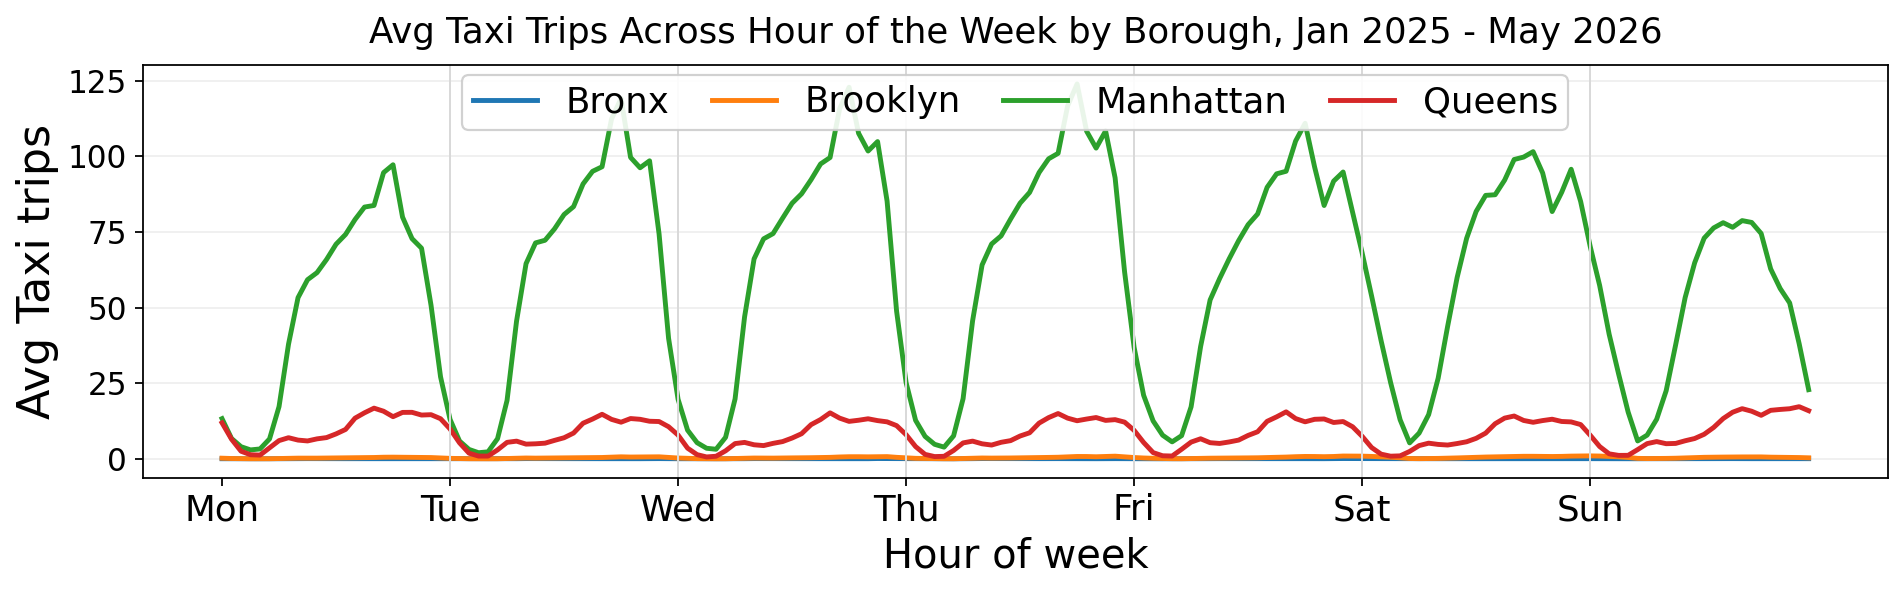

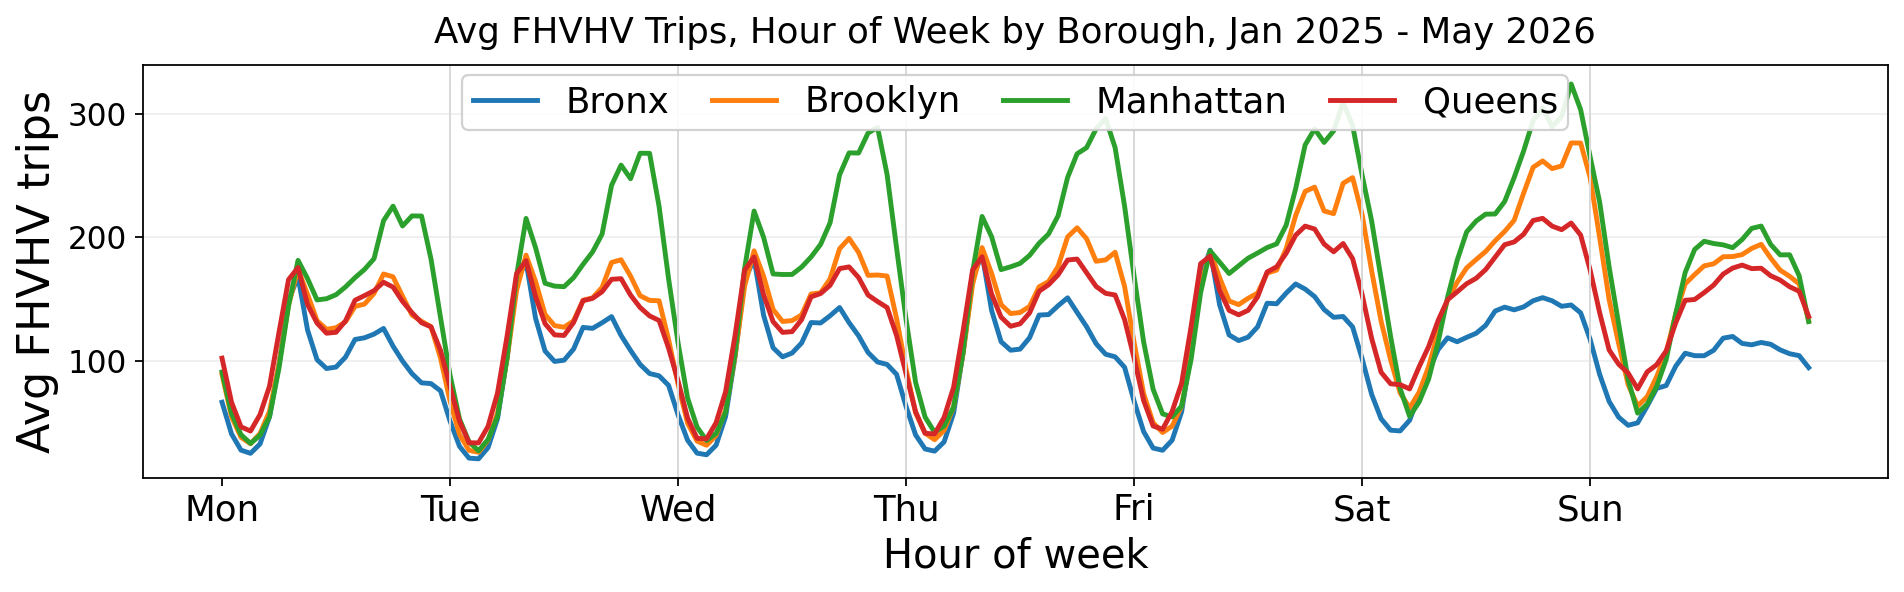

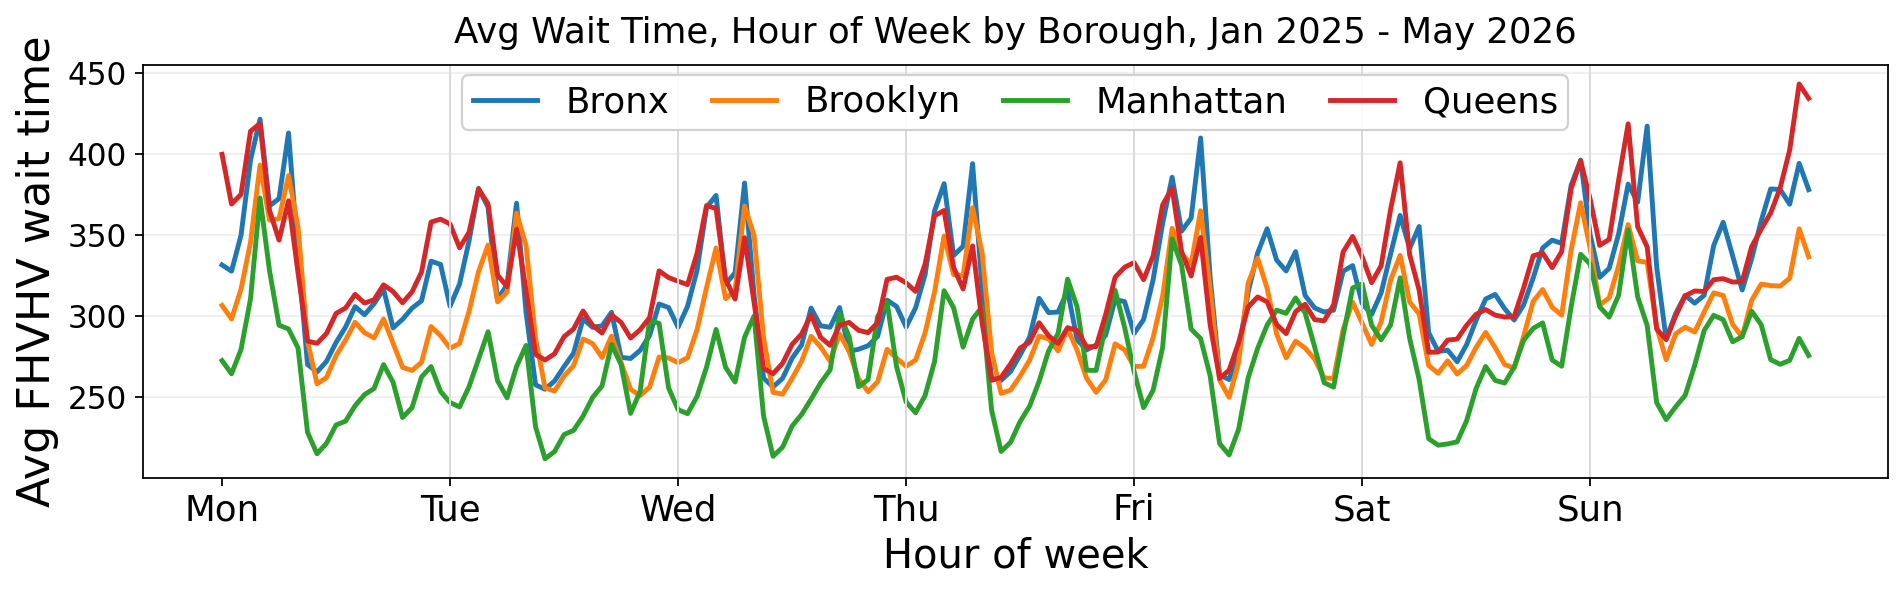

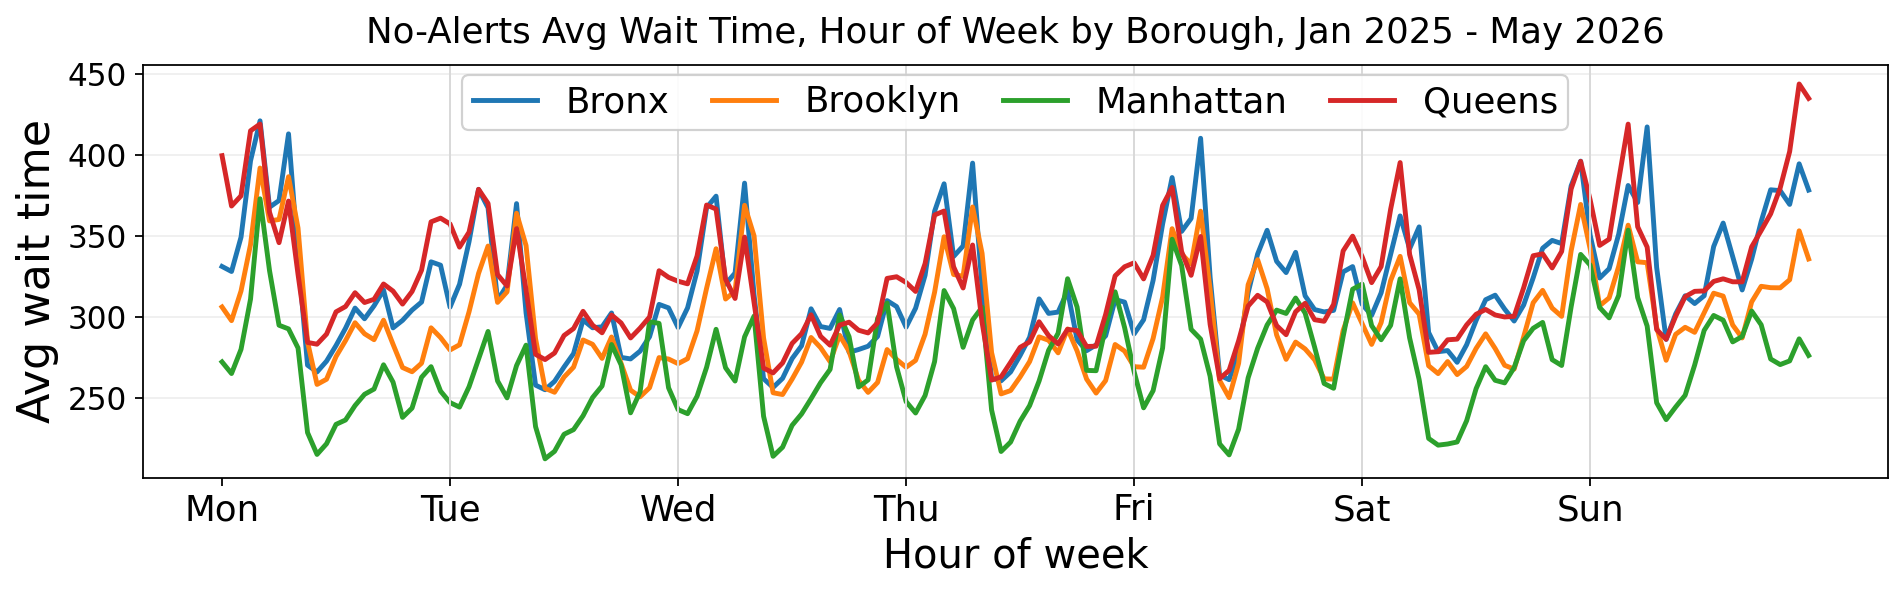

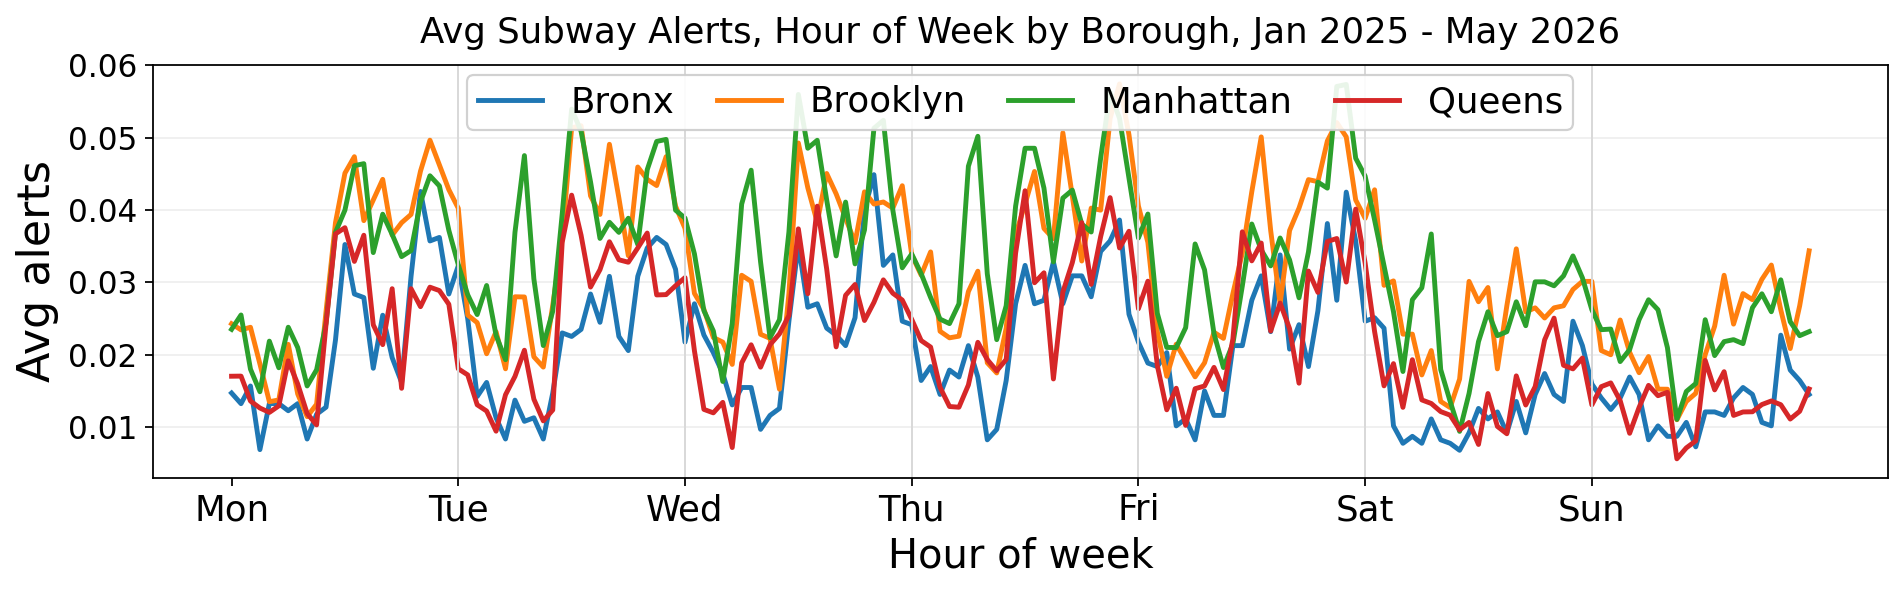

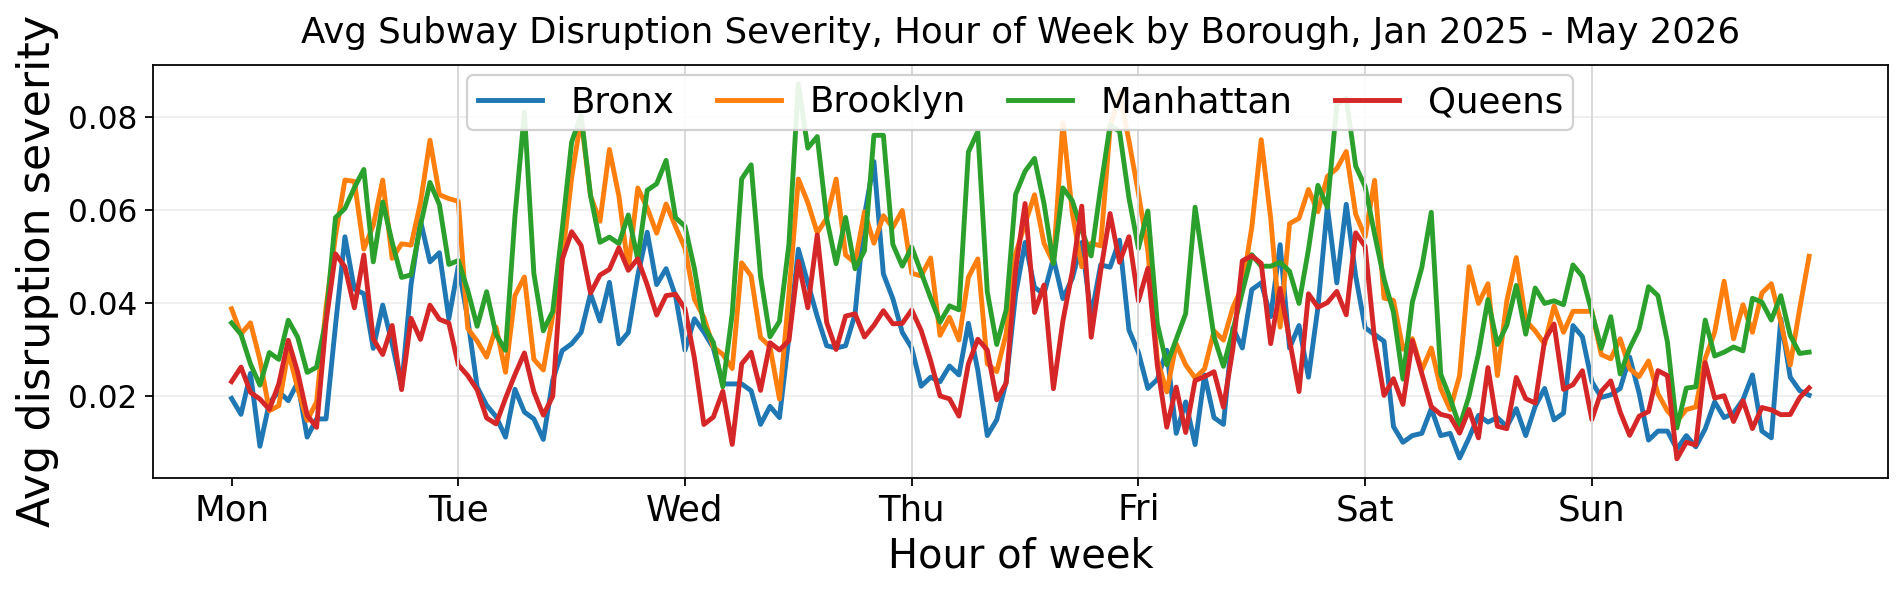

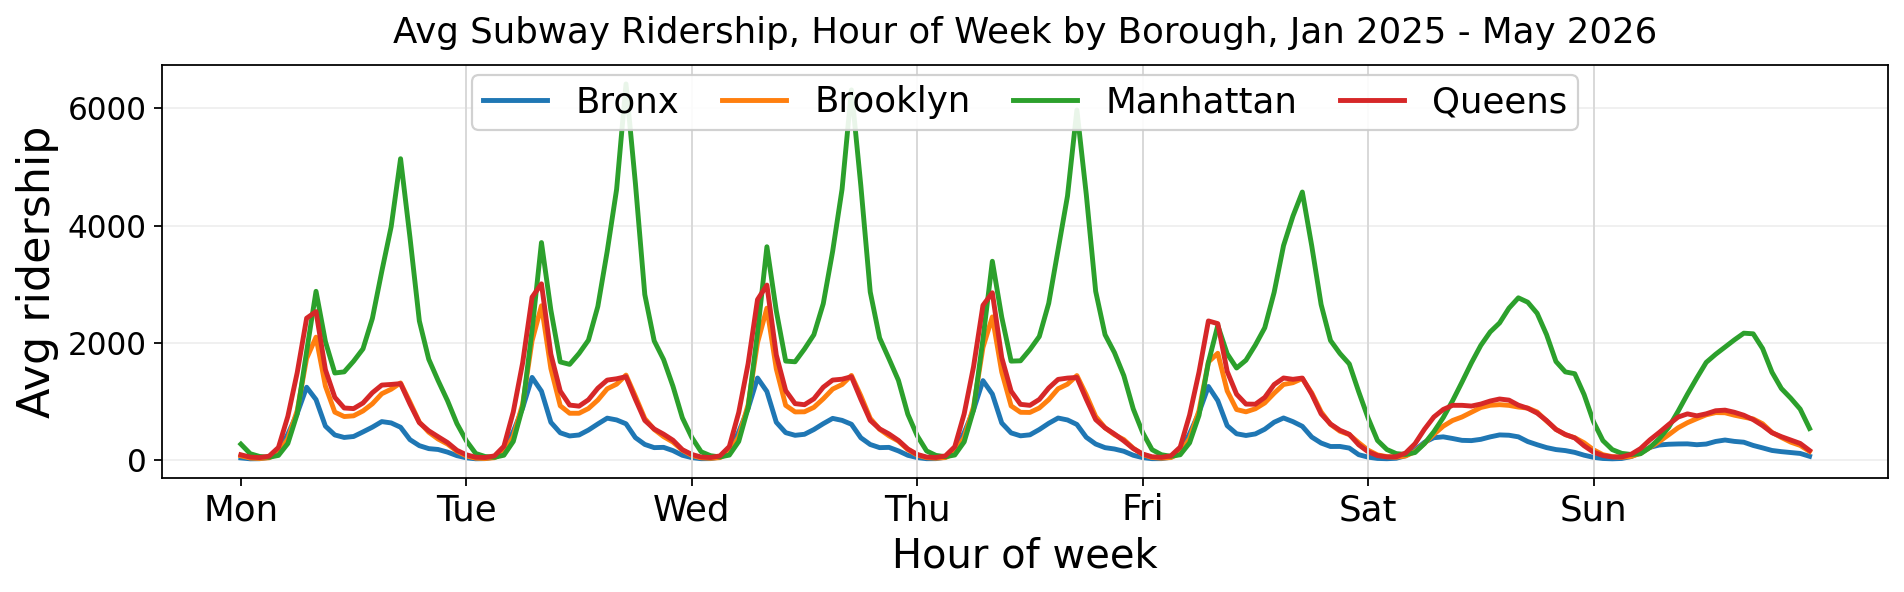

In [26]:
# Plot hour-of-week profiles for attributes of interest 
plot_hour_of_week(
    "n_trips_taxi",
    "Avg Taxi Trips Across Hour of the Week by Borough, Jan 2025 - May 2026",
    "Avg Taxi trips"
)

plot_hour_of_week(
    "n_trips_fhvhv",
    "Avg FHVHV Trips, Hour of Week by Borough, Jan 2025 - May 2026",
    "Avg FHVHV trips"
)

plot_hour_of_week(
    "avg_wait_time_fhvhv", 
    "Avg Wait Time, Hour of Week by Borough, Jan 2025 - May 2026", 
    "Avg FHVHV wait time"
)

plot_hour_of_week(
    "avg_wait_time_fhvhv_no_alert",
    "No-Alerts Avg Wait Time, Hour of Week by Borough, Jan 2025 - May 2026",
    "Avg wait time"
)

plot_hour_of_week(
    "n_alerts",
    "Avg Subway Alerts, Hour of Week by Borough, Jan 2025 - May 2026",
    "Avg alerts"
)

plot_hour_of_week(
    "disruption_severity",
    "Avg Subway Disruption Severity, Hour of Week by Borough, Jan 2025 - May 2026",
    "Avg disruption severity"
)

plot_hour_of_week(
    "ridership",
    "Avg Subway Ridership, Hour of Week by Borough, Jan 2025 - May 2026",
    "Avg ridership"
)

- average taxi trips across hour of the week shows consistent two peak pattern at 6pm (higher peak) and 9pm (lower peak) for manhattan, for tues - sat. I might interpret this as before / after dinner traffic which makes a lot of sense for central district in manhattan. again, non-manhattan boroughs have very lower trip counts.

- average fhvhv trips across hour of the week shows also a two peak pattern at 6 and 9pm, but at more similar peak heights, and across mon - sat. again, translation in the y-axis but similar trends are observed across boroughs.

- average fhvhv wait time across hour of the week shows more sporadic changes especially viewed all at once. Take Manhattan for example, it has a clear dip in wait time just before midday (probably 9-11am, as identified in the hour of day plot), and this dip in wait time is not as significant (lowered but not as low) on weekeneds, compared to weekdays. A similar pattern can be said about the other boroughs, but with two similar dips in wait time prevalent on weekdays, just before midday and just before midnight. Furthermore, the outer boroughs are clustered on early morning (3-5am) peaks on all days of the week, and Manhattan is only clustered together on Monday, Friday, and weekends. 

- average MTA subway alerts across hour of the week shows a very sporadic changes. this is expected as alerts do not necessarily follow the same trend over a long period of time, they probably occur unexpectedly. however, they are deinitely higher during the day on average, across all boroughs, and much lower on weekends compared to weekdays. across the boroughs, there are no clear hourly patterns which are shared. there could be some data which is overrepresented due to a sudden spike in at a particular time. 

- average MTA subway ridership across hour of the week shows two sharp peaks at morning / afternoon peak hours (6-9am, 3-6pm) across all boroughs for weekdays. for manhattan, the afternoon peak (possibly a combination of inbound and outbound) is significantly higher than the morning (probably mostly inbound), for other boroughs, the morning peak (probably mostly outbound with some inbound) is higher (probably mostly inbound). on weekends, the pattern becomes more like a smooth trough over the day, without sharp peaks. this makes sense as people don't necessarily commute at the same peak times on weekends.

Overall, the hour-of-week temporal analysis show regular behavioural cycles, especially for MTA `ridership` and `n_trips_fhvhv`. This can inform modelling choices later.

In [27]:
# Save the temporal sdf as for analysis 
sdf_temporal.write.mode("overwrite").parquet(f"{analysis_dir}/tlc_zone_hourly_temporal")

## Checkpoint
By the end of this Jupyter Notebook, we would have generated some useful geo-spatial and temporal analysis / visualisations.

Importantly, we have gained a better understanding about busy stations / zones, and busy hours / days with respect to attributes `n_trips`, `n_alerts`, and `ridership`. The plots generated are intended to serve as both exploratory data analysis and evidence for downwstream model choices. Also, it highlights some suitable targets to model, such as predictive modelling on the "WHERE" (geo-spatial) and "WHEN" (temporal) of possible recommendations, although the "WHAT" will require our model to inform. 